# CSA17 Artificial Intelligence - Assignment 4 (CO4)
Athisaya U - 192571001

Each module is written with `%%writefile` and imported. Fixed seeds throughout. Raw data goes to `data/`, figures to `figures/`.

In [1]:
import csv, os, math, time, random
import numpy as np
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True)
def save_csv(name, rows):
    with open(os.path.join('data', name), 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
import platform, sklearn; print('Python', platform.python_version(), '| NumPy', np.__version__, '| scikit-learn', sklearn.__version__)

Python 3.13.18 | NumPy 2.5.3 | scikit-learn 1.9.1


## Task 1 and 2 - protocol and decision trees (from scratch)

In [2]:
%%writefile u4_tree.py
# Tasks 1-2 - learning protocol and decision trees implemented from scratch
import math, random
from collections import Counter
import numpy as np

# ---------------- metrics (shared by all tasks) ----------------
def confusion(y_true, y_pred, labels):
    idx = {l: i for i, l in enumerate(labels)}
    m = [[0] * len(labels) for _ in labels]
    for t, p in zip(y_true, y_pred):
        m[idx[t]][idx[p]] += 1
    return m

def prf(y_true, y_pred, positive):
    tp = sum(t == positive and p == positive for t, p in zip(y_true, y_pred))
    fp = sum(t != positive and p == positive for t, p in zip(y_true, y_pred))
    fn = sum(t == positive and p != positive for t, p in zip(y_true, y_pred))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return prec, rec, f1

def accuracy(y_true, y_pred):
    return sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true)

def macro_f1(y_true, y_pred):
    labels = sorted(set(y_true))
    return sum(prf(y_true, y_pred, l)[2] for l in labels) / len(labels)

# ---------------- impurity ----------------
def entropy(labels):
    n = len(labels)
    return -sum(c / n * math.log2(c / n) for c in Counter(labels).values()) if n else 0.0

def gini(labels):
    n = len(labels)
    return 1 - sum((c / n) ** 2 for c in Counter(labels).values()) if n else 0.0

def majority(labels):
    c = Counter(labels)
    return max(sorted(c), key=lambda k: c[k])          # ties broken by label order (reproducible)

# ---------------- categorical ID3 (desk-check table) ----------------
def info_gain(rows, attr, target, impurity=entropy):
    base = impurity([r[target] for r in rows])
    rem = 0.0
    for v in sorted({r[attr] for r in rows}):
        sub = [r[target] for r in rows if r[attr] == v]
        rem += len(sub) / len(rows) * impurity(sub)
    return base - rem

def split_info(rows, attr):
    return entropy([r[attr] for r in rows])

def id3(rows, attrs, target, parent_majority=None, log=None, depth=0, criterion='gain', min_branch=1):
    """Recursive tree construction. Ties are broken by the order of `attrs`."""
    labels = [r[target] for r in rows]
    if not rows:
        return parent_majority                                     # no examples
    if len(set(labels)) == 1:
        return labels[0]                                           # all one class
    if not attrs:
        return majority(labels)                                    # no attributes left
    scores = []
    for a in attrs:
        branches = Counter(r[a] for r in rows)
        if min(branches.values()) < min_branch:
            continue                                               # forbidden: too-small branch
        g = info_gain(rows, a, target)
        s = g / split_info(rows, a) if criterion == 'ratio' and split_info(rows, a) > 0 else g
        scores.append((s, -attrs.index(a), a, g))
    if not scores:
        return majority(labels)
    best = max(scores)[2]
    if log is not None:
        log.append((depth, len(rows), round(entropy(labels), 3), [(a, round(g, 3), round(s, 3)) for s, _, a, g in scores], best))
    tree = {best: {}}
    for v in sorted({r[best] for r in rows}):
        sub = [r for r in rows if r[best] == v]
        tree[best][v] = id3(sub, [a for a in attrs if a != best], target, majority(labels), log, depth + 1, criterion, min_branch)
    return tree

def predict_id3(tree, row, default='Fail'):
    while isinstance(tree, dict):
        a = next(iter(tree))
        tree = tree[a].get(row[a], default)
    return tree

DESK = [dict(No=i + 1, Attendance=a, Assignments=s, Internal=m, Result=r) for i, (a, s, m, r) in enumerate([
    ('High', 'Done', 'Good', 'Pass'), ('High', 'Done', 'Poor', 'Pass'), ('High', 'Missed', 'Good', 'Pass'),
    ('High', 'Missed', 'Poor', 'Fail'), ('Low', 'Done', 'Good', 'Pass'), ('Low', 'Done', 'Poor', 'Fail'),
    ('Low', 'Missed', 'Good', 'Fail'), ('Low', 'Missed', 'Poor', 'Fail')])]
ATTRS = ['Attendance', 'Assignments', 'Internal']

# ---------------- numeric CART-style tree (binary threshold splits) ----------------
class Node:
    __slots__ = ('feature', 'threshold', 'left', 'right', 'label', 'n')
    def __init__(self, label=None, n=0):
        self.feature = self.threshold = self.left = self.right = None
        self.label, self.n = label, n

class TreeClassifier:
    """Binary decision tree on numeric features. criterion: 'entropy' or 'gini'.
    Stopping: pure node, no examples, depth limit, min_samples_split, or no split
    that reduces impurity."""
    def __init__(self, criterion='entropy', max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.criterion, self.max_depth = criterion, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf

    def _imp(self, counts, n):
        if n == 0: return 0.0
        p = counts / n
        if self.criterion == 'gini':
            return 1.0 - np.sum(p * p)
        p = p[p > 0]
        return float(-np.sum(p * np.log2(p)))

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        yi = np.searchsorted(self.classes_, y)
        self.root = self._grow(X, yi, 0)
        return self

    def _best_split(self, X, y):
        n, k = len(y), len(self.classes_)
        parent = self._imp(np.bincount(y, minlength=k).astype(float), n)
        best = (0.0, None, None)
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f], kind='mergesort')
            xs, ys = X[order, f], y[order]
            left = np.zeros(k); right = np.bincount(ys, minlength=k).astype(float)
            for i in range(n - 1):
                left[ys[i]] += 1; right[ys[i]] -= 1
                if xs[i] == xs[i + 1]: continue
                nl = i + 1
                if nl < self.min_samples_leaf or n - nl < self.min_samples_leaf: continue
                gain = parent - (nl / n) * self._imp(left, nl) - ((n - nl) / n) * self._imp(right, n - nl)
                if gain > best[0] + 1e-12:
                    best = (gain, f, (xs[i] + xs[i + 1]) / 2)
        return best

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=len(self.classes_))
        node = Node(label=int(np.argmax(counts)), n=len(y))
        if len(y) == 0 or counts.max() == len(y): return node
        if self.max_depth is not None and depth >= self.max_depth: return node
        if len(y) < self.min_samples_split: return node
        gain, f, t = self._best_split(X, y)
        if f is None: return node
        mask = X[:, f] <= t
        node.feature, node.threshold = f, t
        node.left, node.right = self._grow(X[mask], y[mask], depth + 1), self._grow(X[~mask], y[~mask], depth + 1)
        return node

    def predict(self, X):
        out = []
        for x in np.asarray(X, float):
            node = self.root
            while node.feature is not None:
                node = node.left if x[node.feature] <= node.threshold else node.right
            out.append(self.classes_[node.label])
        return np.array(out)

    def depth(self, node=None):
        node = node or self.root
        return 0 if node.feature is None else 1 + max(self.depth(node.left), self.depth(node.right))

    def leaves(self, node=None):
        node = node or self.root
        return 1 if node.feature is None else self.leaves(node.left) + self.leaves(node.right)

def stratified_split(y, fracs, seed):
    """Indices for train/validation/test (fractions sum to 1), stratified by class."""
    rng = np.random.RandomState(seed)
    parts = [[] for _ in fracs]
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rng.shuffle(idx)
        cuts = np.cumsum([int(round(f * len(idx))) for f in fracs[:-1]])
        for p, chunk in zip(parts, np.split(idx, cuts)):
            p.extend(chunk.tolist())
    return [np.array(sorted(p)) for p in parts]

def kfold(n_or_y, k, seed):
    y = np.asarray(n_or_y)
    rng = np.random.RandomState(seed)
    folds = [[] for _ in range(k)]
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rng.shuffle(idx)
        for i, j in enumerate(idx): folds[i % k].append(j)
    return [np.array(sorted(f)) for f in folds]

Writing u4_tree.py


In [3]:
from u4_tree import *

## Task 1 - faulty versus repaired protocol

In [4]:
%%writefile u4_protocol.py
# Task 1 - the faulty protocol versus the repaired protocol
import numpy as np
from u4_tree import TreeClassifier, stratified_split, kfold, accuracy, prf, confusion, majority

def faulty_protocol(X, y, model):
    """TrainAndTest as submitted: train and test on the same data."""
    model.fit(X, y)
    return accuracy(y, model.predict(X))

def cross_val_accuracy(X, y, make_model, k=5, seed=0):
    folds = kfold(y, k, seed)
    scores = []
    for i in range(k):
        val = folds[i]; trn = np.concatenate([folds[j] for j in range(k) if j != i])
        m = make_model().fit(X[trn], y[trn])
        scores.append(accuracy(y[val], m.predict(X[val])))
    return float(np.mean(scores)), float(np.std(scores))

def repaired_protocol(X, y, depths=(1, 2, 3, 4, 5, 6, 8, None), k=5, seed=42, positive=1):
    """Split once (80/20, stratified, fixed seed); choose max_depth by k-fold CV on the
    training part only; refit; evaluate once on the untouched test set; compare with
    the majority-class baseline."""
    train, test = stratified_split(y, [0.8, 0.2], seed)
    cv = {d: cross_val_accuracy(X[train], y[train], lambda d=d: TreeClassifier('entropy', max_depth=d), k, seed) for d in depths}
    best = max(depths, key=lambda d: (round(cv[d][0], 6), -(d or 99)))     # prefer the shallower tree on ties
    model = TreeClassifier('entropy', max_depth=best).fit(X[train], y[train])
    pred = model.predict(X[test])
    base_label = majority(list(y[train]))
    base = [base_label] * len(test)
    p, r, f = prf(list(y[test]), list(pred), positive)
    bp, br, bf = prf(list(y[test]), base, positive)
    return dict(cv=cv, best_depth=best, test_acc=accuracy(y[test], pred), precision=p, recall=r, f1=f,
                cm=confusion(list(y[test]), list(pred), [0, 1]), baseline_acc=accuracy(y[test], base),
                baseline_f1=bf, train_acc=accuracy(y[train], model.predict(X[train])))

Writing u4_protocol.py


In [5]:
from u4_protocol import *

In [6]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True)          # public UCI Wisconsin breast-cancer data (bundled with scikit-learn)
print('records', len(y), '| class counts (0 = malignant, 1 = benign):', np.bincount(y))
rows = []
for noise in (0.0, 0.10):
    yn = y.copy()
    if noise:
        rng = np.random.RandomState(0); flip = rng.rand(len(y)) < noise; yn[flip] = 1 - yn[flip]
    train_acc = faulty_protocol(X, yn, TreeClassifier('entropy'))
    cv_mean, cv_sd = cross_val_accuracy(X, yn, lambda: TreeClassifier('entropy'), k=5, seed=0)
    tr, te = stratified_split(yn, [0.8, 0.2], 42)
    held = accuracy(yn[te], TreeClassifier('entropy').fit(X[tr], yn[tr]).predict(X[te]))
    rows.append(dict(label_noise=noise, train_on_train=train_acc, cv5=cv_mean, cv_sd=cv_sd, held_out=held, optimism_vs_cv=train_acc - cv_mean))
    print(f"label noise {noise:.0%}: faulty protocol accuracy {train_acc:.3f} | 5-fold CV {cv_mean:.3f} (sd {cv_sd:.3f}) | "
          f"held-out {held:.3f} | optimism {100 * (train_acc - cv_mean):.1f} points")
save_csv('task1_optimism.csv', rows)
r = repaired_protocol(X, y, positive=0)
print('Repaired protocol - CV accuracy by max_depth:', {d: round(v[0], 4) for d, v in r['cv'].items()})
print(f"chosen depth {r['best_depth']} | test accuracy {r['test_acc']:.3f} | precision {r['precision']:.3f} | recall {r['recall']:.3f} | "
      f"F1 {r['f1']:.3f} (positive = malignant) | confusion {r['cm']}")
print(f"majority-class baseline: accuracy {r['baseline_acc']:.3f}, F1 for malignant {r['baseline_f1']:.3f}")

records 569 | class counts (0 = malignant, 1 = benign): [212 357]


label noise 0%: faulty protocol accuracy 1.000 | 5-fold CV 0.951 (sd 0.007) | held-out 0.956 | optimism 4.9 points


label noise 10%: faulty protocol accuracy 1.000 | 5-fold CV 0.733 (sd 0.023) | held-out 0.789 | optimism 26.7 points


Repaired protocol - CV accuracy by max_depth: {1: 0.8947, 2: 0.9145, 3: 0.9386, 4: 0.9342, 5: 0.9364, 6: 0.9364, 8: 0.9364, None: 0.9364}
chosen depth 3 | test accuracy 0.947 | precision 0.950 | recall 0.905 | F1 0.927 (positive = malignant) | confusion [[38, 4], [2, 69]]
majority-class baseline: accuracy 0.628, F1 for malignant 0.000


## Task 2 - desk-check, implementation, pruning, challenge

In [7]:
log = []
tree = id3(DESK, ATTRS, 'Result', log=log)
for depth, n, H, scores, best in log:
    print('  ' * depth + f"node with {n} examples, H = {H}: gains " + ', '.join(f"{a} {g}" for a, g, _ in scores) + f"  -> split on {best}")
print('tree:', tree)
print('training accuracy on the 8 rows:', sum(predict_id3(tree, r) == r['Result'] for r in DESK), '/ 8')

node with 8 examples, H = 1.0: gains Attendance 0.189, Assignments 0.189, Internal 0.189  -> split on Attendance
  node with 4 examples, H = 0.811: gains Assignments 0.311, Internal 0.311  -> split on Assignments
    node with 2 examples, H = 1.0: gains Internal 1.0  -> split on Internal
  node with 4 examples, H = 0.811: gains Assignments 0.311, Internal 0.311  -> split on Assignments
    node with 2 examples, H = 1.0: gains Internal 1.0  -> split on Internal
tree: {'Attendance': {'High': {'Assignments': {'Done': 'Pass', 'Missed': {'Internal': {'Good': 'Pass', 'Poor': 'Fail'}}}}, 'Low': {'Assignments': {'Done': {'Internal': {'Good': 'Pass', 'Poor': 'Fail'}}, 'Missed': 'Fail'}}}}
training accuracy on the 8 rows: 8 / 8


In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
X, y = load_breast_cancer(return_X_y=True)
tr, va, te = stratified_split(y, [0.6, 0.2, 0.2], 0)
rows = []
for crit in ('entropy', 'gini'):
    t0 = time.perf_counter(); mine = TreeClassifier(crit).fit(X[tr], y[tr]); t_mine = time.perf_counter() - t0
    ref = DecisionTreeClassifier(criterion=crit, random_state=0).fit(X[tr], y[tr])
    pm, pr = mine.predict(X[te]), ref.predict(X[te])
    for name, p, depth, leaves in (('from scratch', pm, mine.depth(), mine.leaves()), ('scikit-learn', pr, ref.get_depth(), ref.get_n_leaves())):
        P, R, F = prf(list(y[te]), list(p), 0)
        rows.append(dict(criterion=crit, model=name, accuracy=accuracy(y[te], p), precision=P, recall=R, f1=F, depth=depth, leaves=leaves))
        print(f"{crit:7} {name:12} acc {accuracy(y[te], p):.3f} prec {P:.3f} rec {R:.3f} F1 {F:.3f} (malignant) depth {depth} leaves {leaves} "
              f"confusion {confusion(list(y[te]), list(p), [0, 1])}")
    print(f"        same prediction on {np.mean(pm == pr):.1%} of the {len(te)} test cases; root split: mine feature {mine.root.feature} "
          f"at {mine.root.threshold:.3f}, sklearn feature {ref.tree_.feature[0]} at {ref.tree_.threshold[0]:.3f}; training time {t_mine:.2f} s")
save_csv('task2_trees.csv', rows)

entropy from scratch acc 0.904 prec 0.833 rec 0.930 F1 0.879 (malignant) depth 5 leaves 11 confusion [[40, 3], [8, 64]]
entropy scikit-learn acc 0.922 prec 0.870 rec 0.930 F1 0.899 (malignant) depth 5 leaves 11 confusion [[40, 3], [6, 66]]
        same prediction on 96.5% of the 115 test cases; root split: mine feature 22 at 106.100, sklearn feature 22 at 106.100; training time 0.24 s


gini    from scratch acc 0.904 prec 0.833 rec 0.930 F1 0.879 (malignant) depth 6 leaves 14 confusion [[40, 3], [8, 64]]
gini    scikit-learn acc 0.922 prec 0.854 rec 0.953 F1 0.901 (malignant) depth 6 leaves 14 confusion [[41, 2], [7, 65]]
        same prediction on 96.5% of the 115 test cases; root split: mine feature 22 at 106.100, sklearn feature 22 at 106.100; training time 0.25 s


In [9]:
rows = []
for depth in (1, 2, 3, 4, 5, 6, None):
    for leaf in (1, 5):
        m = TreeClassifier('entropy', max_depth=depth, min_samples_leaf=leaf).fit(X[tr], y[tr])
        r = dict(max_depth=depth or 'full', min_leaf=leaf, depth=m.depth(), leaves=m.leaves(),
                 train=accuracy(y[tr], m.predict(X[tr])), val=accuracy(y[va], m.predict(X[va])), test=accuracy(y[te], m.predict(X[te])))
        rows.append(r)
        print(f"max_depth {str(r['max_depth']):4} min_leaf {leaf}: depth {r['depth']} leaves {r['leaves']:2} | train {r['train']:.3f} val {r['val']:.3f} test {r['test']:.3f}")
best = max(rows, key=lambda r: (r['val'], -r['leaves']))
print('chosen on validation:', best)
save_csv('task2_pruning.csv', rows)

max_depth 1    min_leaf 1: depth 1 leaves  2 | train 0.930 val 0.912 test 0.896
max_depth 1    min_leaf 5: depth 1 leaves  2 | train 0.930 val 0.912 test 0.896


max_depth 2    min_leaf 1: depth 2 leaves  4 | train 0.935 val 0.903 test 0.896
max_depth 2    min_leaf 5: depth 2 leaves  4 | train 0.935 val 0.903 test 0.896


max_depth 3    min_leaf 1: depth 3 leaves  7 | train 0.977 val 0.929 test 0.887
max_depth 3    min_leaf 5: depth 3 leaves  7 | train 0.974 val 0.947 test 0.939


max_depth 4    min_leaf 1: depth 4 leaves  9 | train 0.985 val 0.947 test 0.913


max_depth 4    min_leaf 5: depth 4 leaves  8 | train 0.977 val 0.956 test 0.957
max_depth 5    min_leaf 1: depth 5 leaves 11 | train 1.000 val 0.938 test 0.904


max_depth 5    min_leaf 5: depth 5 leaves  9 | train 0.977 val 0.956 test 0.957


max_depth 6    min_leaf 1: depth 5 leaves 11 | train 1.000 val 0.938 test 0.904


max_depth 6    min_leaf 5: depth 5 leaves  9 | train 0.977 val 0.956 test 0.957


max_depth full min_leaf 1: depth 5 leaves 11 | train 1.000 val 0.938 test 0.904


max_depth full min_leaf 5: depth 5 leaves  9 | train 0.977 val 0.956 test 0.957
chosen on validation: {'max_depth': 4, 'min_leaf': 5, 'depth': 4, 'leaves': 8, 'train': np.float64(0.9765395894428153), 'val': np.float64(0.9557522123893806), 'test': np.float64(0.9565217391304348)}


In [10]:
changed = [dict(r) for r in DESK]; changed[6]['Result'] = 'Pass'           # row 7: Low, Missed, Good -> Pass
log = []; t2 = id3(changed, ATTRS, 'Result', log=log)
print('row 7 changed to Pass -> root gains:', log[0][3], '-> root', log[0][4]); print('new tree:', t2)
with_id = [dict(r, ID=f"S{r['No']}") for r in DESK]
for crit, mb in (('gain', 1), ('ratio', 1), ('gain', 2)):
    log = []; t3 = id3(with_id, ['ID'] + ATTRS, 'Result', log=log, criterion=crit, min_branch=mb)
    print(f"ID attribute added, criterion {crit}, min branch size {mb}: scores (attr, gain, score) {log[0][3]} -> root {log[0][4]}")
from sklearn.datasets import load_breast_cancer
Xb, yb = load_breast_cancer(return_X_y=True)
trb, teb = stratified_split(yb, [0.8, 0.2], 3)
Xid = np.column_stack([np.arange(len(yb)), Xb])                         # row number as a feature
for leaf in (1, 10):
    m = TreeClassifier('entropy', min_samples_leaf=leaf).fit(Xid[trb], yb[trb])
    print(f"breast-cancer data with a row-ID column, min_samples_leaf {leaf}: root feature {m.root.feature} "
          f"({'ID' if m.root.feature == 0 else 'real feature'}), test accuracy {accuracy(yb[teb], m.predict(Xid[teb])):.3f}")

row 7 changed to Pass -> root gains: [('Attendance', 0.049, 0.049), ('Assignments', 0.049, 0.049), ('Internal', 0.549, 0.549)] -> root Internal
new tree: {'Internal': {'Good': 'Pass', 'Poor': {'Attendance': {'High': {'Assignments': {'Done': 'Pass', 'Missed': 'Fail'}}, 'Low': 'Fail'}}}}
ID attribute added, criterion gain, min branch size 1: scores (attr, gain, score) [('ID', 1.0, 1.0), ('Attendance', 0.189, 0.189), ('Assignments', 0.189, 0.189), ('Internal', 0.189, 0.189)] -> root ID
ID attribute added, criterion ratio, min branch size 1: scores (attr, gain, score) [('ID', 1.0, 0.333), ('Attendance', 0.189, 0.189), ('Assignments', 0.189, 0.189), ('Internal', 0.189, 0.189)] -> root ID
ID attribute added, criterion gain, min branch size 2: scores (attr, gain, score) [('Attendance', 0.189, 0.189), ('Assignments', 0.189, 0.189), ('Internal', 0.189, 0.189)] -> root Attendance


breast-cancer data with a row-ID column, min_samples_leaf 1: root feature 28 (real feature), test accuracy 0.938


breast-cancer data with a row-ID column, min_samples_leaf 10: root feature 28 (real feature), test accuracy 0.920


## Task 3 - EM forensics

In [11]:
%%writefile u4_em.py
# Task 3 - EM for a 1-D Gaussian mixture: faulty (unnormalised responsibilities) and repaired
import math
import numpy as np

def normal_pdf(x, mu, var):
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

def log_likelihood(X, pi, mu, var):
    dens = sum(pi[k] * normal_pdf(X, mu[k], var[k]) for k in range(len(pi)))
    return float(np.sum(np.log(np.maximum(dens, 1e-300))))

def em(X, pi, mu, var, T, repaired=True, var_floor=1e-6, trace=None):
    """One E-step and M-step per iteration. The only difference between the two
    versions is the normalisation of r[i][k] over k."""
    X = np.asarray(X, float)
    pi, mu, var = np.array(pi, float), np.array(mu, float), np.array(var, float)
    K = len(pi)
    hist = [dict(ll=log_likelihood(X, pi, mu, var), wsum=float(pi.sum()))]
    for t in range(T):
        r = np.stack([pi[k] * normal_pdf(X, mu[k], var[k]) for k in range(K)], axis=1)    # n x K
        if repaired:
            r = r / np.maximum(r.sum(axis=1, keepdims=True), 1e-300)                     # THE REPAIR
        if trace is not None and t == 0:
            trace['r'] = r.copy()
        Nk = r.sum(axis=0)
        mu = (r * X[:, None]).sum(axis=0) / Nk
        var = np.maximum((r * (X[:, None] - mu) ** 2).sum(axis=0) / Nk, var_floor)
        pi = Nk / len(X)
        if trace is not None and t == 0:
            trace.update(Nk=Nk.copy(), mu=mu.copy(), var=var.copy(), pi=pi.copy())
        hist.append(dict(ll=log_likelihood(X, pi, mu, var), wsum=float(pi.sum())))
    return pi, mu, var, hist

def make_data(seed=0, n=300):
    rng = np.random.RandomState(seed)
    return np.concatenate([rng.normal(-2, 0.8, int(n * 0.4)), rng.normal(3, 1.2, n - int(n * 0.4))])

def random_init(X, K, rng):
    return np.full(K, 1.0 / K), rng.choice(X, K, replace=False), np.full(K, np.var(X))

def many_inits(X, K=2, T=60, runs=20, seed=1):
    rng = np.random.RandomState(seed)
    rows = []
    for r in range(runs):
        pi0, mu0, var0 = random_init(X, K, rng)
        res = {}
        for name, rep in (('faulty', False), ('repaired', True)):
            pi, mu, var, h = em(X, pi0, mu0, var0, T, rep)
            lls = [x['ll'] for x in h]
            drops = sum(1 for a, b in zip(lls, lls[1:]) if b < a - 1e-9)
            res[name] = dict(final_ll=lls[-1], decreases=drops, wsum=h[-1]['wsum'], mu=np.sort(mu))
        rows.append(res)
    return rows

Writing u4_em.py


In [12]:
from u4_em import *

In [13]:
X4 = [1.0, 2.0, 8.0, 9.0]
for rep in (False, True):
    tr = {}; pi, mu, var, h = em(X4, [0.5, 0.5], [2.0, 7.0], [4.0, 4.0], 5, repaired=rep, trace=tr)
    print('REPAIRED' if rep else 'FAULTY', '- first iteration')
    print('   r[i][k] =', np.round(tr['r'], 4).tolist(), '| row sums', np.round(tr['r'].sum(axis=1), 4).tolist())
    print('   Nk =', np.round(tr['Nk'], 4).tolist(), ' mu =', np.round(tr['mu'], 4).tolist(), ' var =', np.round(tr['var'], 4).tolist(), ' pi =', np.round(tr['pi'], 4).tolist())
    print('   log-likelihood per iteration:', [round(x['ll'], 4) for x in h], '| sum of weights:', [round(x['wsum'], 4) for x in h])

FAULTY - first iteration
   r[i][k] = [[0.088, 0.0011], [0.0997, 0.0044], [0.0011, 0.088], [0.0002, 0.0605]] | row sums [0.0891, 0.1041, 0.0891, 0.0607]
   Nk = [0.1891, 0.154]  mu = [1.5777, 8.1717]  var = [0.5547, 1.7402]  pi = [0.0473, 0.0385]
   log-likelihood per iteration: [-9.8993, -16.9256, -22.6014, -28.2773, -33.9532, -39.629] | sum of weights: [1.0, 0.0858, 0.0154, 0.0037, 0.0009, 0.0002]
REPAIRED - first iteration
   r[i][k] = [[0.9876, 0.0124], [0.9579, 0.0421], [0.0124, 0.9876], [0.0036, 0.9964]] | row sums [1.0, 1.0, 1.0, 1.0]
   Nk = [1.9615, 2.0385]  mu = [1.5474, 8.3222]  var = [0.6165, 1.4271]  pi = [0.4904, 0.5096]
   log-likelihood per iteration: [-9.8993, -6.9275, -5.6758, -5.6758, -5.6758, -5.6758] | sum of weights: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


faulty  : mean final log-likelihood    -91313.68 | runs where LL ever decreased 20/20 | mean sum of weights 3.888e-44
repaired: mean final log-likelihood      -631.38 | runs where LL ever decreased  0/20 | mean sum of weights 1


repaired EM  : pi [0.403 0.597] mu [-1.878  2.959] var [0.733 1.319]
scikit-learn : pi [0.403 0.597] mu [-1.875  2.962] var [0.738 1.312]


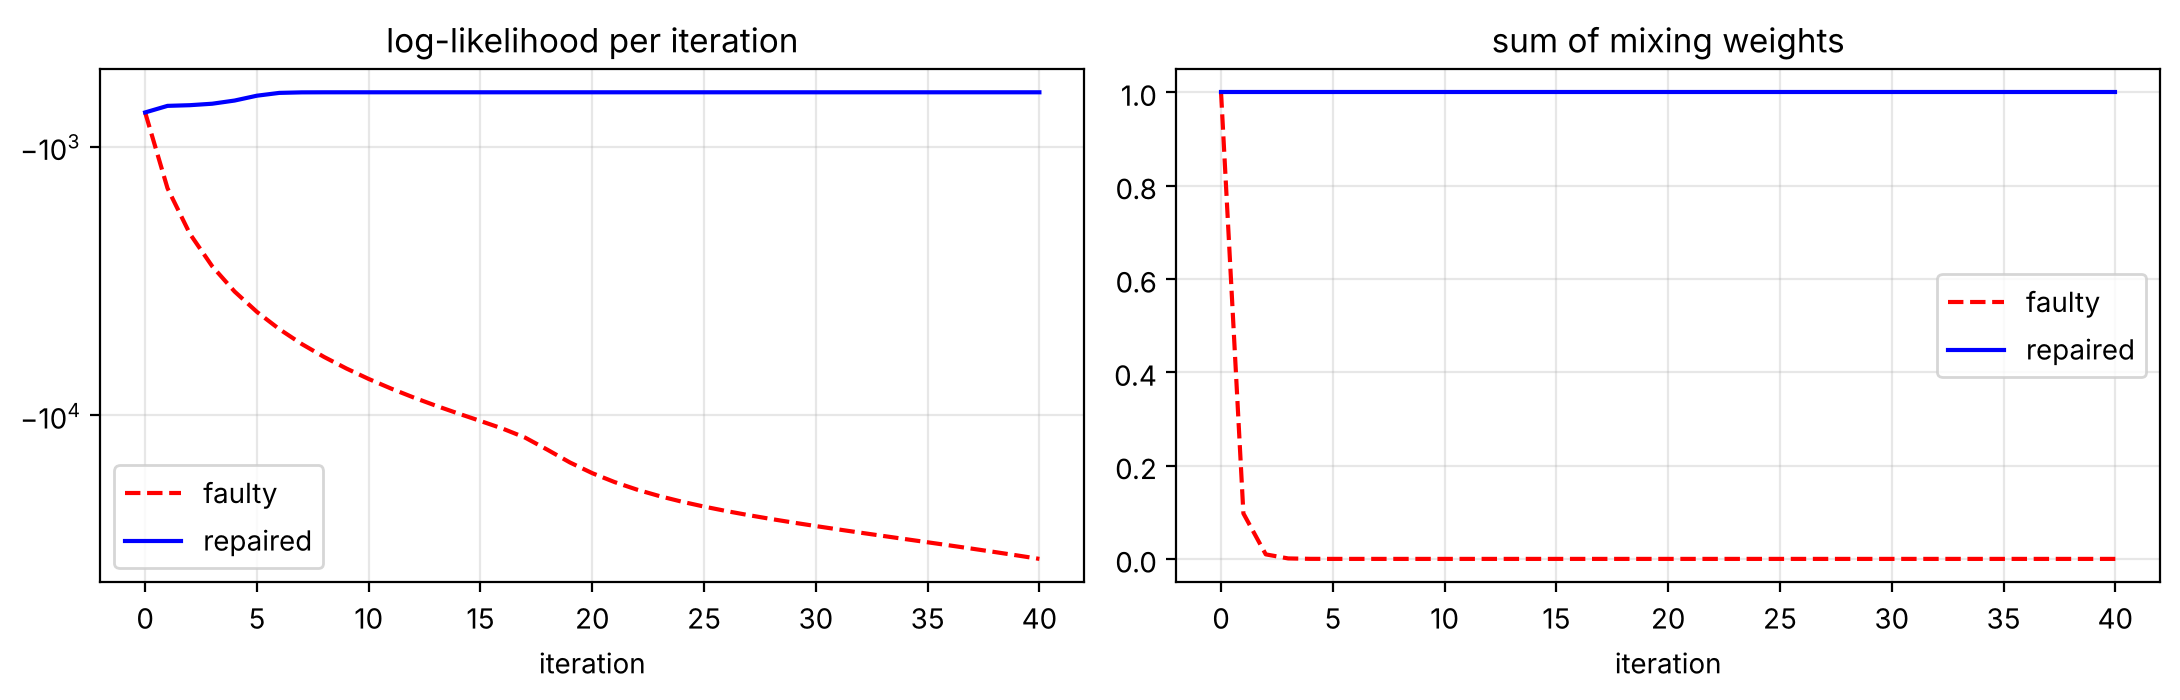

Regression check - symmetric data X = [-1, -1, 1, 1] (every point has the same total density), one iteration:
   original: mu [-0.12435  0.12435] var [0.98454 0.98454] pi [0.08598 0.08598]
   repaired: mu [-0.12435  0.12435] var [0.98454 0.98454] pi [0.5 0.5]


In [14]:
Xd = make_data()
rows = many_inits(Xd, K=2, T=60, runs=20)
summary = []
for name in ('faulty', 'repaired'):
    fl = [r[name]['final_ll'] for r in rows]
    summary.append(dict(version=name, mean_final_ll=np.mean(fl), runs_with_ll_decrease=sum(r[name]['decreases'] > 0 for r in rows),
                        mean_weight_sum=np.mean([r[name]['wsum'] for r in rows])))
    print(f"{name:8}: mean final log-likelihood {np.mean(fl):12.2f} | runs where LL ever decreased {summary[-1]['runs_with_ll_decrease']:2}/20 | "
          f"mean sum of weights {summary[-1]['mean_weight_sum']:.4g}")
save_csv('task3_em_runs.csv', summary)
from sklearn.mixture import GaussianMixture
g = GaussianMixture(2, random_state=0).fit(Xd.reshape(-1, 1))
rng = np.random.RandomState(1); pi0, mu0, var0 = random_init(Xd, 2, rng)
pi, mu, var, _ = em(Xd, pi0, mu0, var0, 200, True)
o = np.argsort(mu)
print('repaired EM  : pi', np.round(pi[o], 3), 'mu', np.round(mu[o], 3), 'var', np.round(var[o], 3))
og = np.argsort(g.means_.ravel())
print('scikit-learn : pi', np.round(g.weights_[og], 3), 'mu', np.round(g.means_.ravel()[og], 3), 'var', np.round(g.covariances_.ravel()[og], 3))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
pi0, mu0, var0 = np.array([0.5, 0.5]), np.array([-1.0, 1.0]), np.array([4.0, 4.0])
for rep, style in ((False, 'r--'), (True, 'b-')):
    _, _, _, h = em(Xd, pi0, mu0, var0, 40, rep)
    ax[0].plot([x['ll'] for x in h], style, label='repaired' if rep else 'faulty')
    ax[1].plot([x['wsum'] for x in h], style, label='repaired' if rep else 'faulty')
ax[0].set_title('log-likelihood per iteration'); ax[0].set_yscale('symlog'); ax[1].set_title('sum of mixing weights')
for a in ax: a.set_xlabel('iteration'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/task3_em.png', dpi=200); plt.show()
print('Regression check - symmetric data X = [-1, -1, 1, 1] (every point has the same total density), one iteration:')
for rep in (False, True):
    pi, mu, var, _ = em([-1.0, -1.0, 1.0, 1.0], [0.5, 0.5], [-0.5, 0.5], [4.0, 4.0], 1, rep)
    print(f"   {'repaired' if rep else 'original'}: mu {np.round(mu, 5)} var {np.round(var, 5)} pi {np.round(pi, 5)}")

## Task 4 - back-propagation

In [15]:
%%writefile u4_nn.py
# Task 4 - fully connected network with back-propagation in NumPy
import numpy as np

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))
ACT = {
    'sigmoid': (sigmoid, lambda z, a: a * (1 - a)),
    'relu': (lambda z: np.maximum(0, z), lambda z, a: (z > 0).astype(float)),
}

class MLP:
    """Layers l = 1..L. Column convention: z(l) = W(l) a(l-1) + b(l), a(l) = g(z(l)).
    W(l) has shape (n_l, n_{l-1}); a batch of m examples is stored as columns."""
    def __init__(self, sizes, hidden='sigmoid', output='sigmoid', loss='mse', seed=0, init_scale=None):
        rng = np.random.RandomState(seed)
        self.sizes, self.hidden, self.output, self.loss = sizes, hidden, output, loss
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            scale = init_scale if init_scale is not None else (np.sqrt(2.0 / n_in) if hidden == 'relu' else np.sqrt(1.0 / n_in))
            self.W.append(rng.randn(n_out, n_in) * scale)
            self.b.append(np.zeros((n_out, 1)))

    def forward(self, X):
        a, cache = X, [(None, X)]
        L = len(self.W)
        for l in range(L):
            z = self.W[l] @ a + self.b[l]
            if l == L - 1:
                if self.output == 'softmax':
                    e = np.exp(z - z.max(axis=0, keepdims=True)); a = e / e.sum(axis=0, keepdims=True)
                else:
                    a = sigmoid(z)
            else:
                a = ACT[self.hidden][0](z)
            cache.append((z, a))
        return a, cache

    def loss_value(self, A, Y):
        m = Y.shape[1]
        if self.loss == 'mse':
            return float(0.5 * np.sum((A - Y) ** 2) / m)
        return float(-np.sum(Y * np.log(np.maximum(A, 1e-12))) / m)

    def backward(self, cache, Y):
        """delta(L) from the loss; delta(l) = (W(l+1)^T delta(l+1)) * g'(z(l)) for l = L-1..1."""
        m = Y.shape[1]
        L = len(self.W)
        grads_W, grads_b, deltas = [None] * L, [None] * L, [None] * L
        zL, aL = cache[L]
        if self.loss == 'mse':
            delta = (aL - Y) * aL * (1 - aL)          # sigmoid output with squared error
        else:
            delta = aL - Y                             # softmax with cross-entropy
        for l in range(L - 1, -1, -1):
            a_prev = cache[l][1]
            deltas[l] = delta
            grads_W[l] = delta @ a_prev.T / m
            grads_b[l] = delta.sum(axis=1, keepdims=True) / m
            if l > 0:
                z, a = cache[l]
                delta = (self.W[l].T @ delta) * ACT[self.hidden][1](z, a)
        return grads_W, grads_b, deltas

    def step(self, gW, gb, lr):
        for l in range(len(self.W)):
            self.W[l] -= lr * gW[l]; self.b[l] -= lr * gb[l]

    def predict(self, X):
        A, _ = self.forward(X)
        return A.argmax(axis=0) if A.shape[0] > 1 else (A[0] >= 0.5).astype(int)

def gradient_check(net, X, Y, eps=1e-5):
    A, cache = net.forward(X)
    gW, gb, _ = net.backward(cache, Y)
    worst = 0.0
    for params, grads in ((net.W, gW), (net.b, gb)):
        for P, G in zip(params, grads):
            it = np.nditer(P, flags=['multi_index'])
            while not it.finished:
                i = it.multi_index; old = P[i]
                P[i] = old + eps; lp = net.loss_value(net.forward(X)[0], Y)
                P[i] = old - eps; lm = net.loss_value(net.forward(X)[0], Y)
                P[i] = old
                num = (lp - lm) / (2 * eps)
                rel = abs(num - G[i]) / max(1e-12, abs(num) + abs(G[i]))
                worst = max(worst, rel)
                it.iternext()
    return worst

def train(net, X, Y, lr, epochs, batch=32, seed=0, Xv=None, Yv=None, record_grads=False):
    """Mini-batch gradient descent; stops early if the loss becomes NaN/inf."""
    rng = np.random.RandomState(seed)
    m = X.shape[1]
    hist = dict(train_loss=[], val_loss=[], grad_norms=[])
    for ep in range(epochs):
        order = rng.permutation(m)
        norms = None
        for s in range(0, m, batch):
            idx = order[s:s + batch]
            A, cache = net.forward(X[:, idx])
            gW, gb, _ = net.backward(cache, Y[:, idx])
            if record_grads and norms is None:
                norms = [float(np.linalg.norm(g)) for g in gW]
            net.step(gW, gb, lr)
        tl = net.loss_value(net.forward(X)[0], Y)
        hist['train_loss'].append(tl)
        if Xv is not None:
            hist['val_loss'].append(net.loss_value(net.forward(Xv)[0], Yv))
        if record_grads: hist['grad_norms'].append(norms)
        if not np.isfinite(tl):
            break
    return hist

def perceptron(X, y, epochs=100, lr=1.0):
    """Single-layer perceptron (step activation) - X rows are examples."""
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        errors = 0
        for xi, yi in zip(X, y):
            p = 1 if xi @ w + b > 0 else 0
            if p != yi:
                w += lr * (yi - p) * xi; b += lr * (yi - p); errors += 1
        if errors == 0: break
    return w, b, np.array([1 if xi @ w + b > 0 else 0 for xi in X])

def desk_check_network():
    net = MLP([2, 2, 1], 'sigmoid', 'sigmoid', 'mse')
    net.W[0] = np.array([[0.5, -0.4], [0.3, 0.8]]); net.b[0] = np.zeros((2, 1))
    net.W[1] = np.array([[0.6, -0.2]]); net.b[1] = np.zeros((1, 1))
    return net

Writing u4_nn.py


In [16]:
from u4_nn import *

In [17]:
net = desk_check_network(); x = np.array([[1.0], [0.0]]); y = np.array([[1.0]])
A, cache = net.forward(x)
print('z(1) =', np.round(cache[1][0].ravel(), 4), ' a(1) =', np.round(cache[1][1].ravel(), 4))
print('z(2) =', np.round(cache[2][0].ravel(), 4), ' y_hat = a(2) =', np.round(A.ravel(), 4), ' E = 0.5(y - y_hat)^2 =', round(net.loss_value(A, y), 4))
gW, gb, deltas = net.backward(cache, y)
print('delta(2) =', np.round(deltas[1].ravel(), 5), ' delta(1) =', np.round(deltas[0].ravel(), 5))
print('dE/dW(2) =', np.round(gW[1], 5).tolist(), ' dE/dW(1) =', np.round(gW[0], 5).tolist())
net.step(gW, gb, 0.5)
print('updated W(1) =', np.round(net.W[0], 5).tolist(), ' W(2) =', np.round(net.W[1], 5).tolist(),
      ' b(1) =', np.round(net.b[0].ravel(), 5).tolist(), ' b(2) =', np.round(net.b[1].ravel(), 5).tolist())

z(1) = [0.5 0.3]  a(1) = [0.6225 0.5744]
z(2) = [0.2586]  y_hat = a(2) = [0.5643]  E = 0.5(y - y_hat)^2 = 0.0949
delta(2) = [-0.10713]  delta(1) = [-0.01511  0.00524]
dE/dW(2) = [[-0.06668, -0.06154]]  dE/dW(1) = [[-0.01511, 0.0], [0.00524, 0.0]]
updated W(1) = [[0.50755, -0.4], [0.29738, 0.8]]  W(2) = [[0.63334, -0.16923]]  b(1) = [0.00755, -0.00262]  b(2) = [0.05356]


In [18]:
rng = np.random.RandomState(0)
for sizes, h, o, l in (([3, 4, 2], 'sigmoid', 'sigmoid', 'mse'), ([4, 5, 3], 'relu', 'softmax', 'ce'), ([4, 6, 6, 3], 'sigmoid', 'softmax', 'ce')):
    n = MLP(sizes, h, o, l, seed=1); Xg = rng.randn(sizes[0], 5); Yg = np.eye(sizes[-1])[:, rng.randint(0, sizes[-1], 5)]
    print(f"gradient check {sizes} {h}/{o}/{l}: max relative error {gradient_check(n, Xg, Yg):.2e}")
Xx = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); yx = np.array([0, 1, 1, 0])
w, b, p = perceptron(Xx, yx, epochs=100)
print('single-layer perceptron on XOR (100 epochs): predictions', p.tolist(), '-> accuracy', (p == yx).mean())
n = MLP([2, 4, 1], 'sigmoid', 'sigmoid', 'mse', seed=3)
h = train(n, Xx.T.astype(float), yx[None, :].astype(float), 2.0, 5000, batch=4)
print('2-4-1 network on XOR: predictions', n.predict(Xx.T.astype(float)).tolist(), '| outputs', np.round(n.forward(Xx.T.astype(float))[0].ravel(), 3).tolist(),
      '| final loss', round(h['train_loss'][-1], 5))

gradient check [3, 4, 2] sigmoid/sigmoid/mse: max relative error 1.13e-09
gradient check [4, 5, 3] relu/softmax/ce: max relative error 1.62e-10
gradient check [4, 6, 6, 3] sigmoid/softmax/ce: max relative error 4.92e-08
single-layer perceptron on XOR (100 epochs): predictions [1, 1, 0, 0] -> accuracy 0.5


2-4-1 network on XOR: predictions [0, 1, 1, 0] | outputs [0.026, 0.974, 0.976, 0.028] | final loss 0.00034


sigmoid hidden  2 lr 0.001: train loss 2.315 | val acc 0.097 | val macro-F1 0.018


sigmoid hidden  2 lr  0.01: train loss 2.207 | val acc 0.184 | val macro-F1 0.132
sigmoid hidden  2 lr   0.1: train loss 1.389 | val acc 0.448 | val macro-F1 0.378


sigmoid hidden  2 lr   1.0: train loss 1.063 | val acc 0.563 | val macro-F1 0.515
sigmoid hidden  8 lr 0.001: train loss 2.278 | val acc 0.078 | val macro-F1 0.051


sigmoid hidden  8 lr  0.01: train loss 1.980 | val acc 0.613 | val macro-F1 0.541
sigmoid hidden  8 lr   0.1: train loss 0.377 | val acc 0.936 | val macro-F1 0.935


sigmoid hidden  8 lr   1.0: train loss 0.046 | val acc 0.972 | val macro-F1 0.972
sigmoid hidden 32 lr 0.001: train loss 2.274 | val acc 0.175 | val macro-F1 0.170


sigmoid hidden 32 lr  0.01: train loss 1.886 | val acc 0.752 | val macro-F1 0.717
sigmoid hidden 32 lr   0.1: train loss 0.213 | val acc 0.955 | val macro-F1 0.955


... (8 outputs left out)

relu    hidden 32 lr   1.0: train loss 0.003 | val acc 0.989 | val macro-F1 0.989


relu    hidden 64 lr 0.001: train loss 1.844 | val acc 0.557 | val macro-F1 0.525
relu    hidden 64 lr  0.01: train loss 0.310 | val acc 0.936 | val macro-F1 0.935


relu    hidden 64 lr   0.1: train loss 0.044 | val acc 0.981 | val macro-F1 0.980
relu    hidden 64 lr   1.0: train loss 0.002 | val acc 0.983 | val macro-F1 0.983


best on validation: relu 32 1.0 -> TEST accuracy 0.961, macro-F1 0.962
test confusion matrix (rows = true digit 0-9):
[[35  0  0  0  0  0  0  0  0  0]
 [ 0 35  1  0  0  0  0  0  1  0]
 [ 0  1 34  1  0  0  0  0  0  0]
 [ 0  0  1 35  0  0  0  0  0  0]
 [ 0  2  0  0 33  0  0  0  0  1]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  1  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 35  0  1]
 [ 0  2  0  0  0  0  0  0 33  0]
 [ 0  0  0  1  0  1  0  0  0 34]]


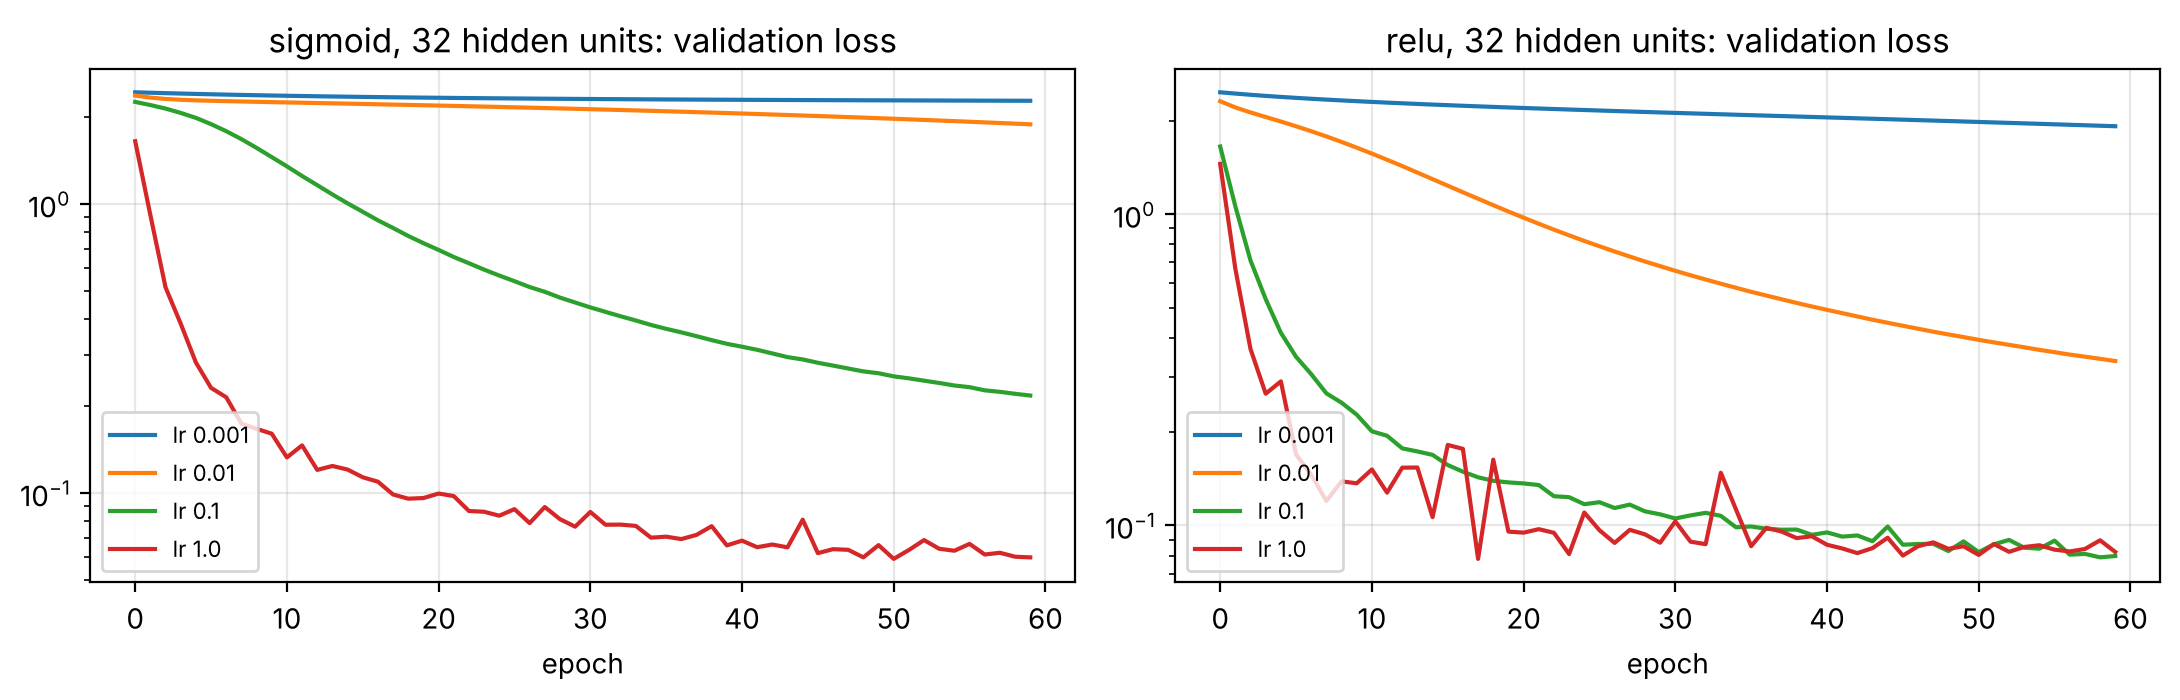

In [19]:
from sklearn.datasets import load_digits
Xd, yd = load_digits(return_X_y=True); Xd = Xd / 16.0          # public 8x8 digits (UCI), bundled with scikit-learn
tr, va, te = stratified_split(yd, [0.6, 0.2, 0.2], 0)
Y = np.eye(10)[yd].T
rows, curves = [], {}
for act in ('sigmoid', 'relu'):
    for hidden in (2, 8, 32, 64):
        for lr in (0.001, 0.01, 0.1, 1.0):
            net = MLP([64, hidden, 10], act, 'softmax', 'ce', seed=0)
            h = train(net, Xd[tr].T, Y[:, tr], lr, 60, batch=32, Xv=Xd[va].T, Yv=Y[:, va])
            p = net.predict(Xd[va].T)
            r = dict(activation=act, hidden=hidden, lr=lr, final_train_loss=h['train_loss'][-1], val_acc=accuracy(list(yd[va]), list(p)),
                     val_macro_f1=macro_f1(list(yd[va]), list(p)))
            rows.append(r); curves[(act, hidden, lr)] = h
            print(f"{act:7} hidden {hidden:2} lr {lr:5}: train loss {r['final_train_loss']:.3f} | val acc {r['val_acc']:.3f} | val macro-F1 {r['val_macro_f1']:.3f}")
save_csv('task4_grid.csv', rows)
best = max(rows, key=lambda r: r['val_macro_f1'])
net = MLP([64, best['hidden'], 10], best['activation'], 'softmax', 'ce', seed=0)
train(net, Xd[tr].T, Y[:, tr], best['lr'], 60, batch=32)
p = net.predict(Xd[te].T)
print('best on validation:', best['activation'], best['hidden'], best['lr'], f"-> TEST accuracy {accuracy(list(yd[te]), list(p)):.3f}, macro-F1 {macro_f1(list(yd[te]), list(p)):.3f}")
print('test confusion matrix (rows = true digit 0-9):'); print(np.array(confusion(list(yd[te]), list(p), list(range(10)))))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, act in enumerate(('sigmoid', 'relu')):
    for lr in (0.001, 0.01, 0.1, 1.0):
        ax[i].plot(curves[(act, 32, lr)]['val_loss'], label=f'lr {lr}')
    ax[i].set_title(f'{act}, 32 hidden units: validation loss'); ax[i].set_xlabel('epoch'); ax[i].set_yscale('log'); ax[i].legend(fontsize=8); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/task4_curves.png', dpi=200); plt.show()

In [20]:
print('Failure 1 - learning rate far too large: ReLU, 64 hidden, learning rate 5.0')
net = MLP([64, 64, 10], 'relu', 'softmax', 'ce', seed=0)
h = train(net, Xd[tr].T, Y[:, tr], 5.0, 10, batch=32, record_grads=True)
for ep, (l, g) in enumerate(zip(h['train_loss'], h['grad_norms'])):
    print(f"   epoch {ep + 1}: train loss {l:10.4f} | gradient norm per layer (W1, W2) {np.round(g, 3).tolist()}")
print('Failure 2 - vanishing gradient: 6 sigmoid hidden layers of 32, lr 0.1')
deep = MLP([64, 32, 32, 32, 32, 32, 32, 10], 'sigmoid', 'softmax', 'ce', seed=0)
h = train(deep, Xd[tr].T, Y[:, tr], 0.1, 30, batch=32, record_grads=True)
for ep in (0, 9, 29):
    print(f"   epoch {ep + 1}: loss {h['train_loss'][ep]:.3f} | grad norm layer 1..7 {np.round(h['grad_norms'][ep], 5).tolist()}")
print('   val accuracy after 30 epochs:', round(accuracy(list(yd[va]), list(deep.predict(Xd[va].T))), 3))
fix = MLP([64, 32, 32, 32, 32, 32, 32, 10], 'relu', 'softmax', 'ce', seed=0)
h2 = train(fix, Xd[tr].T, Y[:, tr], 0.1, 30, batch=32, record_grads=True)
print('   same depth with ReLU + He initialisation: grad norms epoch 1', np.round(h2['grad_norms'][0], 4).tolist(),
      '| val accuracy', round(accuracy(list(yd[va]), list(fix.predict(Xd[va].T))), 3))

Failure 1 - learning rate far too large: ReLU, 64 hidden, learning rate 5.0
   epoch 1: train loss     2.3697 | gradient norm per layer (W1, W2) [0.99, 1.022]
   epoch 2: train loss     2.3803 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 3: train loss     2.4211 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 4: train loss     2.3572 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 5: train loss     2.3711 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 6: train loss     2.3324 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 7: train loss     2.3730 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 8: train loss     2.4006 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 9: train loss     2.3672 | gradient norm per layer (W1, W2) [0.0, 0.0]
   epoch 10: train loss     2.3654 | gradient norm per layer (W1, W2) [0.0, 0.0]
Failure 2 - vanishing gradient: 6 sigmoid hidden layers of 32, lr 0.1


   epoch 1: loss 2.307 | grad norm layer 1..7 [0.00018, 0.00053, 0.00197, 0.01094, 0.04666, 0.19629, 0.75783]
   epoch 10: loss 2.304 | grad norm layer 1..7 [0.00012, 0.00025, 0.00088, 0.00582, 0.03089, 0.1385, 0.5129]
   epoch 30: loss 2.305 | grad norm layer 1..7 [0.00014, 0.00043, 0.00137, 0.00585, 0.03579, 0.1344, 0.40298]
   val accuracy after 30 epochs: 0.1
   same depth with ReLU + He initialisation: grad norms epoch 1 [1.0451, 0.8818, 0.7907, 0.9046, 1.1683, 1.0218, 0.7362] | val accuracy 0.992


## Task 5.1 / 5.2 - Naive Bayes and kernel machines

In [21]:
%%writefile u4_grid.py
# Task 5.1-5.2 - substation-state data, Naive Bayes from scratch, SVM comparison
import math, time
import numpy as np

FEATURES = ['load_pct', 'oil_temp', 'ambient', 'voltage_pu', 'fan_on']

def substation_data(n=2000, seed=7, noise=0.03):
    """Synthetic but physically motivated substation records. Hazard (1) when the
    transformer is overloaded AND hot, or when voltage leaves the 0.92-1.08 p.u.
    band (too low or too high) - a rule no single straight line can separate."""
    rng = np.random.RandomState(seed)
    load = rng.uniform(40, 140, n)
    ambient = rng.uniform(10, 48, n)
    fan = (rng.rand(n) < 0.8).astype(float)
    oil = 30 + 0.45 * load + 0.5 * ambient - 8 * fan + rng.normal(0, 5, n)
    volt = 1.0 - 0.0008 * (load - 90) + rng.normal(0, 0.045, n)
    hazard = ((load > 105) & (oil > 85)) | (np.abs(volt - 1.0) > 0.08)
    flip = rng.rand(n) < noise
    y = np.where(flip, ~hazard, hazard).astype(int)
    X = np.column_stack([load, oil, ambient, volt, fan])
    return X, y

class NaiveBayes:
    """Categorical NB on binned features. Parameters by maximum-likelihood counts with
    Laplace (additive) smoothing alpha. Works in log space."""
    def __init__(self, alpha=1.0, bins=6):
        self.alpha, self.bins = alpha, bins

    def _discretise(self, X):
        return np.column_stack([np.digitize(X[:, j], self.edges[j]) for j in range(X.shape[1])])

    def fit(self, X, y):
        self.edges = [np.unique(np.quantile(X[:, j], np.linspace(0, 1, self.bins + 1)[1:-1])) for j in range(X.shape[1])]
        D = self._discretise(X)
        self.classes = np.unique(y)
        self.log_prior = np.log(np.array([np.mean(y == c) for c in self.classes]))
        self.log_lik = []                                    # per feature: (classes x values)
        for j in range(D.shape[1]):
            V = len(self.edges[j]) + 1
            table = np.zeros((len(self.classes), V))
            for ci, c in enumerate(self.classes):
                counts = np.bincount(D[y == c, j], minlength=V).astype(float)
                with np.errstate(divide='ignore'):
                    table[ci] = np.log((counts + self.alpha) / (counts.sum() + self.alpha * V))
            self.log_lik.append(table)
        return self

    def joint_log(self, X):
        D = self._discretise(X)
        s = np.tile(self.log_prior, (len(D), 1))
        for j, table in enumerate(self.log_lik):
            s = s + table[:, D[:, j]].T
        return s

    def predict_proba(self, X):
        s = self.joint_log(X)
        m = np.max(s, axis=1, keepdims=True)
        with np.errstate(invalid='ignore'):
            p = np.exp(s - m); p = p / p.sum(axis=1, keepdims=True)
        p[~np.isfinite(p).all(axis=1)] = np.exp(self.log_prior)      # every class impossible: fall back to the prior
        return p

    def predict(self, X):
        return self.classes[np.argmax(self.predict_proba(X), axis=1)]

def log_loss(y, p1):
    p_true = np.where(np.asarray(y) == 1, p1, 1 - np.asarray(p1, float))
    with np.errstate(divide='ignore'):
        return float(np.mean(-np.log(p_true)))           # inf if a true class got probability 0

def toy_zero_count():
    """Three training examples; 'Fan=off' is never seen with Normal, so P(off|Normal)=0."""
    train = [('High', 'off', 'Hazard'), ('High', 'on', 'Normal'), ('Low', 'on', 'Normal')]
    query = ('High', 'off')
    out = {}
    for alpha in (0, 1):
        res = {}
        for c in ('Hazard', 'Normal'):
            rows = [r for r in train if r[2] == c]
            prior = len(rows) / len(train)
            p_load = (sum(r[0] == query[0] for r in rows) + alpha) / (len(rows) + 2 * alpha)
            p_fan = (sum(r[1] == query[1] for r in rows) + alpha) / (len(rows) + 2 * alpha)
            res[c] = (round(prior, 3), round(p_load, 3), round(p_fan, 3), round(prior * p_load * p_fan, 4))
        out[alpha] = res
    # query 2: a Hazard pattern never seen with Load=Low: both classes may hit zero
    q2 = ('Low', 'off')
    res = {}
    for c in ('Hazard', 'Normal'):
        rows = [r for r in train if r[2] == c]
        p = len(rows) / 3 * (sum(r[0] == q2[0] for r in rows) / len(rows)) * (sum(r[1] == q2[1] for r in rows) / len(rows))
        res[c] = p
    out['unseen'] = res
    return out

Writing u4_grid.py


In [22]:
from u4_grid import *

In [23]:
toy = toy_zero_count()
for a in (0, 1):
    print(f"toy table, alpha={a}: query (Load=High, Fan=off) ->", {c: dict(zip(('prior', 'P(load|c)', 'P(fan|c)', 'score'), v)) for c, v in toy[a].items()})
print('query (Load=Low, Fan=off) with alpha=0 -> scores', toy['unseen'], '(every class impossible: no decision)')
Xg, yg = substation_data()
print('substation records', len(yg), '| hazardous', int(yg.sum()), '| features', FEATURES)
tr, va, te = stratified_split(yg, [0.6, 0.2, 0.2], 1)
rows = []
for ntrain in (len(tr), 200):
    sub = tr if ntrain == len(tr) else np.random.RandomState(0).choice(tr, ntrain, replace=False)
    for a in (0, 0.1, 1, 10):
        nb = NaiveBayes(a, bins=20).fit(Xg[sub], yg[sub])
        prob = nb.predict_proba(Xg[te]); pred = nb.predict(Xg[te])
        zero = float(np.isinf(nb.joint_log(Xg[te])).any(axis=1).mean())
        P, R, F = prf(list(yg[te]), list(pred), 1)
        rows.append(dict(train_size=len(sub), alpha=a, accuracy=accuracy(list(yg[te]), list(pred)), precision=P, recall=R, f1=F,
                         log_loss=log_loss(yg[te], prob[:, 1]), test_rows_with_zero=zero))
        print(f"train {len(sub):4} alpha {a:4}: acc {rows[-1]['accuracy']:.3f} prec {P:.3f} rec {R:.3f} F1 {F:.3f} | log-loss {rows[-1]['log_loss']:.4f} | "
              f"test rows hitting a zero probability {zero:.1%}")
save_csv('task5_naive_bayes.csv', rows)

toy table, alpha=0: query (Load=High, Fan=off) -> {'Hazard': {'prior': 0.333, 'P(load|c)': 1.0, 'P(fan|c)': 1.0, 'score': 0.3333}, 'Normal': {'prior': 0.667, 'P(load|c)': 0.5, 'P(fan|c)': 0.0, 'score': 0.0}}
toy table, alpha=1: query (Load=High, Fan=off) -> {'Hazard': {'prior': 0.333, 'P(load|c)': 0.667, 'P(fan|c)': 0.667, 'score': 0.1481}, 'Normal': {'prior': 0.667, 'P(load|c)': 0.5, 'P(fan|c)': 0.25, 'score': 0.0833}}
query (Load=Low, Fan=off) with alpha=0 -> scores {'Hazard': 0.0, 'Normal': 0.0} (every class impossible: no decision)
substation records 2000 | hazardous 724 | features ['load_pct', 'oil_temp', 'ambient', 'voltage_pu', 'fan_on']
train 1200 alpha    0: acc 0.905 prec 0.864 rec 0.876 F1 0.870 | log-loss 0.2802 | test rows hitting a zero probability 0.0%
train 1200 alpha  0.1: acc 0.905 prec 0.864 rec 0.876 F1 0.870 | log-loss 0.2799 | test rows hitting a zero probability 0.0%
train 1200 alpha    1: acc 0.902 prec 0.858 rec 0.876 F1 0.867 | log-loss 0.2769 | test rows hitt

SVM linear               {'svc__C': 0.01}                     SVs 832  | test acc 0.880 | F1 0.830 | search time 2.65 s
SVM rbf                  {'svc__C': 1, 'svc__gamma': 1}       SVs 512  | test acc 0.932 | F1 0.904 | search time 3.42 s
Naive Bayes (alpha 1)    20 bins                              SVs -    | test acc 0.905 | F1 0.870 | search time - s
Task 2 tree (depth 4)    depth chosen on validation           SVs -    | test acc 0.945 | F1 0.919 | search time - s


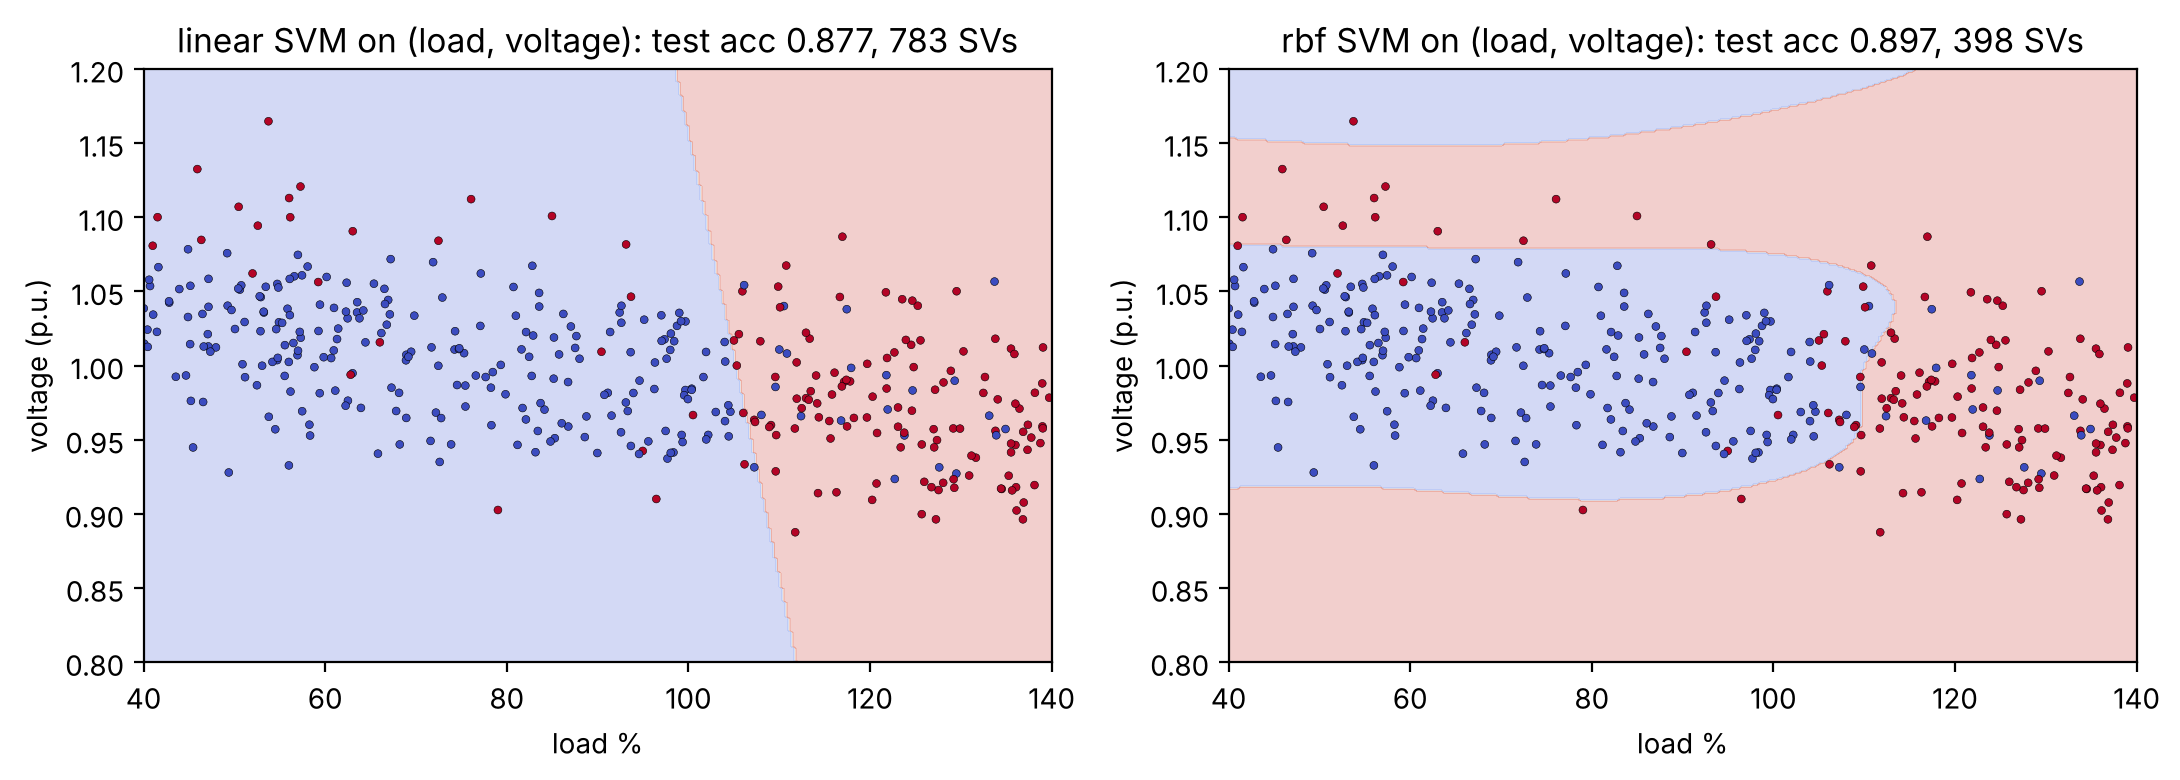

In [24]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
trv = np.concatenate([tr, va])
rows = []
for kernel, grid in (('linear', {'svc__C': [0.01, 0.1, 1, 10, 100]}), ('rbf', {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.01, 0.1, 1, 10]})):
    t0 = time.perf_counter()
    g = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=kernel)), grid, cv=5).fit(Xg[trv], yg[trv])
    secs = time.perf_counter() - t0
    pred = g.predict(Xg[te]); P, R, F = prf(list(yg[te]), list(pred), 1)
    rows.append(dict(model=f'SVM {kernel}', params=str(g.best_params_), support_vectors=int(g.best_estimator_[-1].n_support_.sum()),
                     accuracy=accuracy(list(yg[te]), list(pred)), f1=F, search_seconds=secs))
nb = NaiveBayes(1.0, bins=20).fit(Xg[trv], yg[trv]); pred = nb.predict(Xg[te])
rows.append(dict(model='Naive Bayes (alpha 1)', params='20 bins', support_vectors='-', accuracy=accuracy(list(yg[te]), list(pred)), f1=prf(list(yg[te]), list(pred), 1)[2], search_seconds='-'))
depths = {d: accuracy(list(yg[va]), list(TreeClassifier('entropy', max_depth=d).fit(Xg[tr], yg[tr]).predict(Xg[va]))) for d in (2, 3, 4, 5, 6, 8, None)}
bd = max(depths, key=lambda d: (depths[d], -(d or 99)))
tree = TreeClassifier('entropy', max_depth=bd).fit(Xg[trv], yg[trv]); pred = tree.predict(Xg[te])
rows.append(dict(model=f'Task 2 tree (depth {bd})', params='depth chosen on validation', support_vectors='-', accuracy=accuracy(list(yg[te]), list(pred)),
                 f1=prf(list(yg[te]), list(pred), 1)[2], search_seconds='-'))
for r in rows:
    print(f"{r['model']:24} {r['params']:36} SVs {str(r['support_vectors']):4} | test acc {r['accuracy']:.3f} | F1 {r['f1']:.3f} | search time {r['search_seconds'] if isinstance(r['search_seconds'], str) else round(r['search_seconds'], 2)} s")
save_csv('task5_models.csv', rows)
import matplotlib.pyplot as plt
cols = [0, 3]                                          # load_pct, voltage_pu
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xx, yy = np.meshgrid(np.linspace(40, 140, 300), np.linspace(0.8, 1.2, 300))
for a, kernel in zip(ax, ('linear', 'rbf')):
    m = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=10, gamma='scale')).fit(Xg[trv][:, cols], yg[trv])
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, zz, alpha=0.25, cmap='coolwarm')
    a.scatter(Xg[te][:, 0], Xg[te][:, 3], c=yg[te], cmap='coolwarm', s=8, edgecolor='k', linewidth=0.2)
    acc = accuracy(list(yg[te]), list(m.predict(Xg[te][:, cols])))
    a.set_title(f'{kernel} SVM on (load, voltage): test acc {acc:.3f}, {m[-1].n_support_.sum()} SVs'); a.set_xlabel('load %'); a.set_ylabel('voltage (p.u.)')
plt.tight_layout(); plt.savefig('figures/task5_boundaries.png', dpi=200); plt.show()

## Task 5.3 - explanation-based learning

In [25]:
%%writefile u4_fol.py
# First-order core shared by Tasks 3-7: terms, UNIFY, substitution composition,
# backward chaining (with negation as failure and built-ins) and forward chaining.
import itertools, sys
sys.setrecursionlimit(20000)

# Variables are strings starting with '?'; constants are other strings or numbers;
# compound terms and atoms are tuples (functor, arg1, ..., argn).
def is_var(t): return isinstance(t, str) and t.startswith('?')

class Stats:
    def __init__(self):
        self.unify = 0; self.goals = 0; self.max_depth = 0; self.inferences = 0

def walk(t, s):
    while is_var(t) and t in s:
        t = s[t]
    return t

def subst(s, t):
    """Apply substitution s to term t (fully)."""
    t = walk(t, s)
    if isinstance(t, tuple):
        return (t[0],) + tuple(subst(s, a) for a in t[1:])
    return t

def occurs(v, t, s):
    t = walk(t, s)
    if t == v: return True
    return isinstance(t, tuple) and any(occurs(v, a, s) for a in t[1:])

def unify(x, y, s=None, occurs_check=True, st=None):
    """Most general unifier extending s, or None. Bindings are kept in triangular
    form and resolved by walk(); subst() gives the composed result."""
    if st is not None: st.unify += 1
    s = {} if s is None else s
    stack = [(x, y)]
    s = dict(s)
    while stack:
        a, b = stack.pop()
        a, b = walk(a, s), walk(b, s)
        if a == b:
            continue
        if is_var(a):
            if occurs_check and occurs(a, b, s): return None
            s[a] = b
        elif is_var(b):
            if occurs_check and occurs(b, a, s): return None
            s[b] = a
        elif isinstance(a, tuple) and isinstance(b, tuple) and a[0] == b[0] and len(a) == len(b):
            stack.extend(zip(a[1:], b[1:]))
        else:
            return None
    return s

def compose(s1, s2):
    """Composition s1∘s2: apply s1 first, then s2 (as in SUBST(COMPOSE(θ1,θ2), p) =
    SUBST(θ2, SUBST(θ1, p)))."""
    out = {v: subst(s2, t) for v, t in s1.items()}
    for v, t in s2.items():
        if v not in out: out[v] = t
    return {v: t for v, t in out.items() if v != t}

def resolved(s):
    return {v: subst(s, t) for v, t in s.items()}

_counter = itertools.count()
def variables(t, out=None):
    out = set() if out is None else out
    if is_var(t): out.add(t)
    elif isinstance(t, tuple):
        for a in t[1:]: variables(a, out)
    return out

def standardize(rule):
    """Rename rule variables apart (fresh names for every use)."""
    head, body = rule
    vs = variables(head)
    for b in body: variables(b, vs)
    k = next(_counter)
    m = {v: f'{v}_{k}' for v in vs}
    return subst(m, head), [subst(m, b) for b in body]

BUILTINS = {'>=': lambda a, b: a >= b, '<': lambda a, b: a < b, '!=': lambda a, b: a != b}

class KB:
    """Definite clauses (head, [body]) plus facts indexed by predicate and by
    (predicate, argument position, value) so that any bound argument can be used."""
    def __init__(self, rules=(), facts=()):
        self.rules, self.by_head = [], {}
        self.facts, self.index, self.by_pred = set(), {}, {}
        for r in rules: self.add_rule(r)
        for f in facts: self.tell(f)
    def add_rule(self, r):
        self.rules.append(r); self.by_head.setdefault(r[0][0], []).append(r)
    def tell(self, f):
        if f in self.facts: return False
        self.facts.add(f)
        self.by_pred.setdefault(f[0], []).append(f)
        for i, a in enumerate(f[1:], 1):
            if not isinstance(a, tuple):
                self.index.setdefault((f[0], i, a), []).append(f)
        return True
    def candidates(self, goal):
        best = self.by_pred.get(goal[0], [])
        for i, a in enumerate(goal[1:], 1):
            if not is_var(a) and not isinstance(a, tuple):
                lst = self.index.get((goal[0], i, a), [])
                if len(lst) < len(best): best = lst
        return best

def bc_ask(kb, goal, st=None, depth_limit=10_000):
    """Backward chaining (depth-first, left-to-right) yielding substitutions."""
    st = st or Stats()
    def solve(goals, s, depth):
        if not goals:
            yield s; return
        g, rest = goals[0], goals[1:]
        if g[0] == 'not':                      # negation as failure (closed world)
            for _ in solve([g[1]], s, depth + 1):
                return
            yield from solve(rest, s, depth); return
        if g[0] in BUILTINS:
            a, b = subst(s, g[1]), subst(s, g[2])
            if BUILTINS[g[0]](a, b):
                yield from solve(rest, s, depth)
            return
        st.goals += 1; st.max_depth = max(st.max_depth, depth)
        if depth > depth_limit:
            raise RecursionError('depth limit')
        g2 = subst(s, g)
        for f in kb.candidates(g2):
            s2 = unify(g2, f, s, False, st)
            if s2 is not None:
                yield from solve(rest, s2, depth)
        for r in kb.by_head.get(g[0], []):
            head, body = standardize(r)
            s2 = unify(g2, head, s, False, st)
            if s2 is not None:
                st.inferences += 1
                yield from solve(body + rest, s2, depth + 1)
    yield from solve([goal], {}, 0)

def show_t(t):
    if isinstance(t, tuple):
        return f"{t[0]}({', '.join(show_t(a) for a in t[1:])})"
    return str(t)

Writing u4_fol.py


In [26]:
from u4_fol import *

## Task 5.3 - EBL

In [27]:
%%writefile u4_ebl.py
# Task 5.3 - explanation-based learning of a hazard rule from one explained case
from u4_fol import unify, subst, standardize, variables, show_t, Stats, BUILTINS, is_var

s_, p_, a_, t_, v_ = '?s', '?p', '?a', '?t', '?v'
THEORY = [
    ('R1', ('Hazard', s_), [('Overloaded', s_), ('CoolingImpaired', s_)]),
    ('R2', ('Hazard', s_), [('VoltageUnstable', s_)]),
    ('R3', ('Overloaded', s_), [('LoadPct', s_, p_), ('>=', p_, 105)]),
    ('R4', ('CoolingImpaired', s_), [('Fan', s_, 'off'), ('AmbientHot', s_)]),
    ('R5', ('CoolingImpaired', s_), [('OilTemp', s_, t_), ('>=', t_, 90)]),
    ('R6', ('AmbientHot', s_), [('Ambient', s_, a_), ('>=', a_, 40)]),
    ('R7', ('VoltageUnstable', s_), [('Voltage', s_, v_), ('<', v_, 0.92)]),
    ('R8', ('VoltageUnstable', s_), [('Voltage', s_, v_), ('>=', v_, 1.08)]),
]
OPERATIONAL = {'LoadPct', 'Fan', 'Ambient', 'OilTemp', 'Voltage'} | set(BUILTINS)

def prove(goal, facts, rules, st, s=None, depth=0):
    """Backward chaining that yields (substitution, explanation tree)."""
    s = {} if s is None else s
    g = subst(s, goal)
    if g[0] in BUILTINS:
        if BUILTINS[g[0]](g[1], g[2]):
            yield s, (g, 'built-in', [])
        return
    st.goals += 1; st.max_depth = max(st.max_depth, depth)
    for f in facts:
        if f[0] == g[0] and len(f) == len(g):
            s2 = unify(g, f, s, False, st)
            if s2 is not None:
                yield s2, (f, 'fact', [])
    for name, head, body in rules:
        h, b = standardize((head, body))
        s2 = unify(g, h, s, False, st)
        if s2 is None: continue
        st.inferences += 1
        def chain(goals, s3):
            if not goals:
                yield s3, []; return
            for s4, tree in prove(goals[0], facts, rules, st, s3, depth + 1):
                for s5, rest in chain(goals[1:], s4):
                    yield s5, [tree] + rest
        for s3, kids in chain(b, s2):
            yield s3, (subst(s3, h), name, kids)

def show_tree(tree, depth=0, out=None):
    out = [] if out is None else out
    atom, how, kids = tree
    out.append('    ' * depth + f'{show_t(atom)}   [{how}]')
    for k in kids: show_tree(k, depth + 1, out)
    return out

def generalise(goal_pred, tree, rules):
    """EBG: replay the explanation with variables instead of the example's constants.
    Each rule used is re-applied to a general goal; the operational leaves under the
    general substitution form the body of the learned rule."""
    rule_by = {n: (h, b) for n, h, b in rules}
    leaves = []
    def replay(general_goal, node, s):
        atom, how, kids = node
        if how in ('fact', 'built-in'):
            leaves.append(general_goal); return s
        h, b = standardize(rule_by[how])
        s = unify(general_goal, h, s, False)
        for sub_goal, kid in zip(b, kids):
            s = replay(sub_goal, kid, s)
        return s
    head = (goal_pred, '?x')
    s = replay(head, tree, {})
    body = [subst(s, l) for l in leaves]
    # rename variables neatly
    names, k = {}, iter('xyzuvw')
    def tidy(t):
        if is_var(t):
            if t not in names: names[t] = '?' + next(k)
            return names[t]
        return (t[0],) + tuple(tidy(a) for a in t[1:]) if isinstance(t, tuple) else t
    head, body = tidy(subst(s, head)), [tidy(l) for l in body]
    assert all(l[0] in OPERATIONAL for l in body)
    return ('LEARNED', head, body)

def case(name, load, fan, ambient, oil, volt):
    return [('LoadPct', name, load), ('Fan', name, fan), ('Ambient', name, ambient), ('OilTemp', name, oil), ('Voltage', name, volt)]

TRAIN_EXAMPLE = case('S17', 112, 'off', 43, 80, 0.98)

TEST_CASES = [   # (name, load, fan, ambient, oil, volt) - designed to cover every path
    ('T1', 110, 'off', 42, 82, 1.00), ('T2', 120, 'off', 45, 88, 0.99), ('T3', 105, 'off', 40, 79, 1.01),
    ('T4', 130, 'off', 47, 95, 0.97), ('T5', 115, 'off', 41, 70, 1.02),                                   # learned path
    ('T6', 112, 'on', 43, 92, 1.00), ('T7', 108, 'on', 30, 95, 0.99),                                     # overload + hot oil (R5)
    ('T8', 80, 'on', 30, 60, 0.88), ('T9', 95, 'on', 25, 70, 1.10), ('T10', 60, 'off', 44, 65, 0.90),      # voltage (R7/R8)
    ('T11', 104, 'off', 45, 85, 1.00), ('T12', 112, 'off', 39, 85, 1.00), ('T13', 112, 'on', 43, 85, 1.00),  # boundary misses
    ('T14', 90, 'off', 46, 80, 1.00), ('T15', 70, 'on', 20, 55, 1.00), ('T16', 100, 'on', 35, 89, 0.95),
    ('T17', 140, 'on', 48, 89, 1.07), ('T18', 106, 'off', 40, 91, 0.93), ('T19', 50, 'on', 15, 45, 1.05),
    ('T20', 118, 'off', 10, 75, 1.00),
]

def evaluate_cases(learned):
    rows = []
    for name, *vals in TEST_CASES:
        facts = case(name, *vals)
        st_t, st_l = Stats(), Stats()
        theory = next(prove(('Hazard', name), facts, THEORY, st_t), None) is not None
        lr = next(prove(('Hazard', name), facts, [learned], st_l), None) is not None
        rows.append(dict(case=name, theory=theory, learned=lr, theory_goals=st_t.goals, theory_unify=st_t.unify,
                         learned_goals=st_l.goals, learned_unify=st_l.unify))
    return rows

Writing u4_ebl.py


In [28]:
from u4_ebl import *

In [29]:
for name, head, body in THEORY:
    print(f"{name}: {show_t(head)} <= {' AND '.join(show_t(b) for b in body)}")
st = Stats(); s, tree = next(prove(('Hazard', 'S17'), TRAIN_EXAMPLE, THEORY, st))
print('Explanation of the training case S17:'); print('\n'.join('   ' + l for l in show_tree(tree)))
learned = generalise('Hazard', tree, THEORY)
print('LEARNED RULE:', show_t(learned[1]), '<=', ' AND '.join(show_t(b) for b in learned[2]))
rows = evaluate_cases(learned)
for r in rows:
    print(f"{r['case']:3}: domain theory {str(r['theory']):5} ({r['theory_goals']:2} goals, {r['theory_unify']:3} unifications) | "
          f"learned rule {str(r['learned']):5} ({r['learned_goals']} goals, {r['learned_unify']} unifications)")
save_csv('task5_ebl.csv', rows)
fired = [r for r in rows if r['learned']]
print(f"hazard by theory {sum(r['theory'] for r in rows)}/20 | learned rule fires {len(fired)}/20 | learned but not theory {sum(r['learned'] and not r['theory'] for r in rows)}")
print(f"on the cases where the rule fires: {np.mean([r['learned_unify'] for r in fired]):.1f} vs {np.mean([r['theory_unify'] for r in fired]):.1f} unifications; "
      f"over all 20 cases: {np.mean([r['learned_unify'] for r in rows]):.1f} vs {np.mean([r['theory_unify'] for r in rows]):.1f}")

R1: Hazard(?s) <= Overloaded(?s) AND CoolingImpaired(?s)
R2: Hazard(?s) <= VoltageUnstable(?s)
R3: Overloaded(?s) <= LoadPct(?s, ?p) AND >=(?p, 105)
R4: CoolingImpaired(?s) <= Fan(?s, off) AND AmbientHot(?s)
R5: CoolingImpaired(?s) <= OilTemp(?s, ?t) AND >=(?t, 90)
R6: AmbientHot(?s) <= Ambient(?s, ?a) AND >=(?a, 40)
R7: VoltageUnstable(?s) <= Voltage(?s, ?v) AND <(?v, 0.92)
R8: VoltageUnstable(?s) <= Voltage(?s, ?v) AND >=(?v, 1.08)
Explanation of the training case S17:
   Hazard(S17)   [R1]
       Overloaded(S17)   [R3]
           LoadPct(S17, 112)   [fact]
           >=(112, 105)   [built-in]
       CoolingImpaired(S17)   [R4]
           Fan(S17, off)   [fact]
           AmbientHot(S17)   [R6]
               Ambient(S17, 43)   [fact]
               >=(43, 40)   [built-in]
LEARNED RULE: Hazard(?x) <= LoadPct(?x, ?y) AND >=(?y, 105) AND Fan(?x, off) AND Ambient(?x, ?z) AND >=(?z, 40)
T1 : domain theory True  ( 7 goals,  17 unifications) | learned rule True  (4 goals, 4 unifications)
T

## Task 6 - reinforcement-learning controller

In [30]:
%%writefile u4_rl.py
# Task 6 - energy-aware lecture-hall air-conditioning controller: simulator, Q-learning, baseline
import math
import numpy as np

ACTIONS = ['Off', 'Low', 'High']
POWER_KW = [0.0, 1.5, 3.5]            # electrical power of each action
COOLING = [0.0, 0.9, 1.9]             # degrees C removed per 15-minute slot
SLOT_H = 0.25
START_H, END_H = 6.0, 20.0            # an episode is one day, 06:00-20:00 (56 slots)
N_SLOTS = int((END_H - START_H) / SLOT_H)
COMFORT = (22.0, 26.0)

def price_at(hour, pattern='normal'):
    """Time-of-use tariff (Rs per kWh)."""
    if pattern == 'spike' and 8.0 <= hour < 9.0:
        return 25.0                                     # adversarial: pre-arrival price spike
    if 14.0 <= hour < 18.0: return 10.0
    if 6.0 <= hour < 14.0: return 7.0
    return 4.0

def price_level(p):
    return 0 if p <= 4 else 1 if p <= 7 else 2

class HallSim:
    """Room temperature: T' = T + k_env (T_out - T) + heat_people * occupied - cooling[a] + noise."""
    def __init__(self, seed, price_pattern='normal', k_env=0.12, heat_people=0.9):
        self.rng = np.random.RandomState(seed)
        self.pattern, self.k_env, self.heat = price_pattern, k_env, heat_people

    def reset(self):
        r = self.rng
        self.t = 0
        self.peak = 33 + r.uniform(-3, 3)                 # hottest outdoor temperature today
        self.lectures = []
        for start, end in ((9.0, 12.0), (13.0, 17.0)):
            if r.rand() < 0.9:                            # 10% chance a block is cancelled
                shift = r.choice([-0.25, 0.0, 0.0, 0.25])
                self.lectures.append((start + shift, end))
        self.T = self.outdoor(START_H) + 1.0
        return self.observe()

    def hour(self, t=None):
        return START_H + SLOT_H * (self.t if t is None else t)

    def outdoor(self, h):
        return self.peak - 6 + 6 * math.sin((h - 9) / 24 * 2 * math.pi)

    def occupied(self, h):
        return any(s <= h < e for s, e in self.lectures)

    def observe(self):
        h = self.hour()
        nxt = min([s - h for s, e in self.lectures if s > h] or [99])
        return dict(slot=self.t, T=self.T, occupied=self.occupied(h), price=price_at(h, self.pattern),
                    T_out=self.outdoor(h), hour=h, next_in=nxt)

    def step(self, a, comfort_weight=10.0):
        h = self.hour()
        occ = self.occupied(h)
        kwh = POWER_KW[a] * SLOT_H
        cost = kwh * price_at(h, self.pattern)
        self.T = self.T + self.k_env * (self.outdoor(h) - self.T) + self.heat * occ - COOLING[a] + self.rng.normal(0, 0.1)
        self.t += 1
        h2 = self.hour()
        occ2 = self.occupied(h2)
        viol = max(0.0, self.T - COMFORT[1]) + max(0.0, COMFORT[0] - self.T) if occ2 else 0.0
        reward = -cost - comfort_weight * viol
        done = self.t >= N_SLOTS
        return self.observe(), reward, done, dict(kwh=kwh, cost=cost, violation=viol > 0, viol_deg=viol)

def encode(obs, features=('slot', 'T', 'occupied', 'price')):
    """Discrete state: slot (0..55), temperature bucket (1 C, 18..35), occupancy, price level."""
    key = []
    if 'slot' in features: key.append(obs['slot'])
    if 'hour' in features: key.append(int(obs['hour']))                      # 1-hour bucket
    if 'until' in features:                                                     # time to next lecture
        n = obs.get('next_in', 99)
        key.append(0 if obs['occupied'] else 1 if n <= 0.5 else 2 if n <= 1.0 else 3)
    if 'part' in features: key.append(0 if obs['hour'] < 12 else 1 if obs['hour'] < 14 else 2 if obs['hour'] < 18 else 3)
    if 'soon' in features: key.append(int(not obs['occupied'] and obs.get('next_in', 99) <= 0.5))
    if 'T' in features: key.append(int(np.clip(round(obs['T'] * 2), 36, 70)))         # 0.5 C buckets
    if 'occupied' in features: key.append(int(obs['occupied']))
    if 'price' in features: key.append(price_level(obs['price']))
    return tuple(key)

def q_learning(seed, episodes=3000, alpha=None, gamma=0.97, eps_start=1.0, eps_end=0.02,
               features=('slot', 'T', 'occupied', 'price'), price_pattern='normal'):
    rng = np.random.RandomState(seed + 1000)
    env = HallSim(seed, price_pattern)
    Q, N = {}, {}
    curve = []
    for ep in range(episodes):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / (0.7 * episodes))
        obs = env.reset(); s = encode(obs, features); total = 0.0
        done = False
        while not done:
            q = Q.setdefault(s, np.zeros(3))
            a = rng.randint(3) if rng.rand() < eps else int(np.argmax(q))
            obs2, r, done, info = env.step(a)
            s2 = encode(obs2, features)
            q2 = Q.setdefault(s2, np.zeros(3))
            target = r if done else r + gamma * np.max(q2)
            n = N.setdefault(s, np.zeros(3)); n[a] += 1
            lr = alpha if alpha is not None else max(0.02, 1.0 / n[a] ** 0.6)     # visit-count step size
            q[a] += lr * (target - q[a])
            s, total = s2, total + r
        curve.append(total)
    return Q, curve

def greedy_policy(Q, features):
    def act(obs):
        q = Q.get(encode(obs, features))
        return 0 if q is None else int(np.argmax(q))
    return act

def thermostat(obs):
    """Fixed-rule baseline: during the published timetable window 08:45-17:00, cool when warm."""
    if 8.75 <= obs['hour'] < 17.0:
        if obs['T'] > 25.0: return 2
        if obs['T'] > 24.0: return 1
    return 0

def evaluate(policy, days=30, seed=500, price_pattern='normal', log_day=None):
    env = HallSim(seed, price_pattern)
    tot = dict(reward=0.0, kwh=0.0, cost=0.0, violations=0, viol_deg=0.0, arrival_viol=0)
    trace = []
    for d in range(days):
        obs = env.reset(); done = False
        while not done:
            a = policy(obs)
            prev = obs
            obs, r, done, info = env.step(a)
            tot['reward'] += r; tot['kwh'] += info['kwh']; tot['cost'] += info['cost']
            tot['violations'] += info['violation']; tot['viol_deg'] += info['viol_deg']
            if info['violation'] and not prev['occupied'] and obs['occupied']: tot['arrival_viol'] += 1
            if log_day is not None and d == log_day:
                trace.append((round(prev['hour'], 2), round(prev['T'], 1), int(prev['occupied']), prev['price'], ACTIONS[a]))
    out = {k: v / days for k, v in tot.items()}
    return (out, trace) if log_day is not None else out

def episodes_to_converge(curve, window=100, tol=0.05):
    sm = np.convolve(curve, np.ones(window) / window, mode='valid')
    final = np.mean(curve[-window:])
    for i, v in enumerate(sm):
        if abs(v - final) <= tol * abs(final):
            return i + window
    return len(curve)

def toy_desk_check():
    """3 states (Cool, Warm, Hot) x 2 actions (Off, On); deterministic toy transitions."""
    T = {('Cool', 'Off'): ('Warm', 0), ('Cool', 'On'): ('Cool', -2), ('Warm', 'Off'): ('Hot', -1),
         ('Warm', 'On'): ('Cool', -2), ('Hot', 'Off'): ('Hot', -10), ('Hot', 'On'): ('Warm', -2)}
    Q = {(s, a): 0.0 for s in ('Cool', 'Warm', 'Hot') for a in ('Off', 'On')}
    alpha, gamma = 0.5, 0.9
    steps = [('Cool', 'Off'), ('Warm', 'Off'), ('Hot', 'Off'), ('Hot', 'On'), ('Warm', 'On'), ('Cool', 'Off')]
    log = []
    for s, a in steps:
        s2, r = T[(s, a)]
        best_next = max(Q[(s2, 'Off')], Q[(s2, 'On')])
        old = Q[(s, a)]
        Q[(s, a)] = old + alpha * (r + gamma * best_next - old)
        log.append((s, a, r, s2, old, best_next, Q[(s, a)]))
    return log, Q

Writing u4_rl.py


In [31]:
from u4_rl import *

In [32]:
log, Q = toy_desk_check()
print('alpha = 0.5, gamma = 0.9; Q starts at 0')
for i, (s, a, r, s2, old, best, new) in enumerate(log, 1):
    print(f"update {i}: {s:4} --{a:3}--> reward {r:4} next {s2:4} | Q old {old:6.3f} + 0.5*({r} + 0.9*{best:.3f} - {old:.3f}) = {new:7.3f}")
print('final Q table:', {k: round(v, 3) for k, v in Q.items()})

alpha = 0.5, gamma = 0.9; Q starts at 0
update 1: Cool --Off--> reward    0 next Warm | Q old  0.000 + 0.5*(0 + 0.9*0.000 - 0.000) =   0.000
update 2: Warm --Off--> reward   -1 next Hot  | Q old  0.000 + 0.5*(-1 + 0.9*0.000 - 0.000) =  -0.500
update 3: Hot  --Off--> reward  -10 next Hot  | Q old  0.000 + 0.5*(-10 + 0.9*0.000 - 0.000) =  -5.000
update 4: Hot  --On --> reward   -2 next Warm | Q old  0.000 + 0.5*(-2 + 0.9*0.000 - 0.000) =  -1.000
update 5: Warm --On --> reward   -2 next Cool | Q old  0.000 + 0.5*(-2 + 0.9*0.000 - 0.000) =  -1.000
update 6: Cool --Off--> reward    0 next Warm | Q old  0.000 + 0.5*(0 + 0.9*-0.500 - 0.000) =  -0.225
final Q table: {('Cool', 'Off'): -0.225, ('Cool', 'On'): 0.0, ('Warm', 'Off'): -0.5, ('Warm', 'On'): -1.0, ('Hot', 'Off'): -5.0, ('Hot', 'On'): -1.0}


per test day (30 unseen days)   Q-learning (20 seeds)        fixed-rule thermostat
total reward                  -195.41 +/-  3.71         -198.06
energy cost (Rs)               178.61 +/-  3.93          178.82
energy (kWh)                    21.38 +/-  0.54           21.38
comfort violations (slots)       3.85 +/-  0.91            3.77
violation degree-slots           1.68 +/-  0.28            1.92
violations at arrival            0.09 +/-  0.05            0.17
episodes to convergence: 10215.70 +/- 284.50 | states visited:   344.70 +/-  2.33


one test day, Q-learning policy (hour, T, occupied, price, action) from 08:00 to 10:00: [(8.0, 22.1, 0, 7.0, 'Off'), (8.25, 22.2, 0, 7.0, 'Off'), (8.5, 22.2, 0, 7.0, 'Off'), (8.75, 22.4, 0, 7.0, 'Off'), (9.0, 22.6, 0, 7.0, 'Off'), (9.25, 22.8, 1, 7.0, 'Off'), (9.5, 23.9, 1, 7.0, 'Off'), (9.75, 25.1, 1, 7.0, 'Low')]


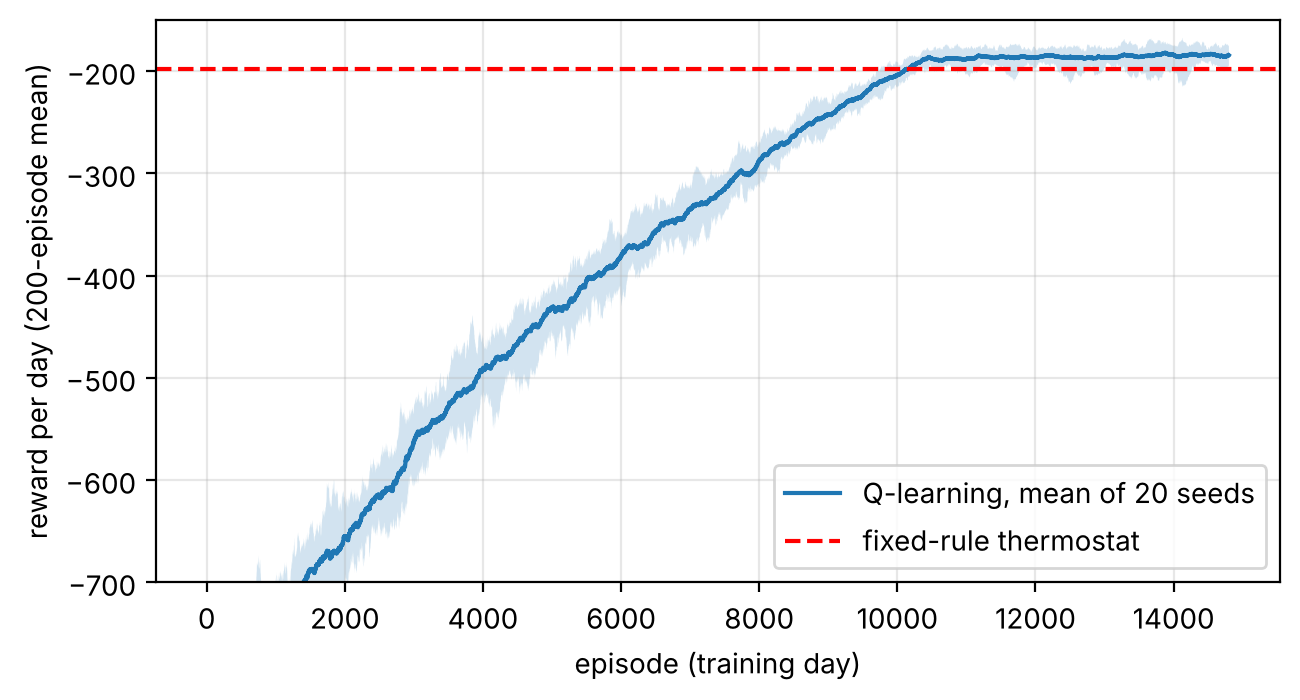

In [33]:
F = ('until', 'part', 'T')
base = evaluate(thermostat, days=30, seed=500)
rows, curves = [], []
for seed in range(20):
    Q, curve = q_learning(seed, 15000, features=F)
    r = evaluate(greedy_policy(Q, F), days=30, seed=500)
    r.update(seed=seed, states=len(Q), episodes_to_converge=episodes_to_converge(curve))
    rows.append(r); curves.append(curve)
save_csv('task6_seeds.csv', rows)
def ms(k): v = [r[k] for r in rows]; return f"{np.mean(v):8.2f} +/- {np.std(v):5.2f}"
print('per test day (30 unseen days)   Q-learning (20 seeds)        fixed-rule thermostat')
for k, label in (('reward', 'total reward'), ('cost', 'energy cost (Rs)'), ('kwh', 'energy (kWh)'), ('violations', 'comfort violations (slots)'),
                 ('viol_deg', 'violation degree-slots'), ('arrival_viol', 'violations at arrival')):
    print(f"{label:28} {ms(k)}        {base[k]:8.2f}")
print('episodes to convergence:', ms('episodes_to_converge'), '| states visited:', ms('states'))
_, trace_q = evaluate(greedy_policy(*[q_learning(0, 15000, features=F)[0]], F), days=1, seed=777, log_day=0)
print('one test day, Q-learning policy (hour, T, occupied, price, action) from 08:00 to 10:00:', [t for t in trace_q if 8.0 <= t[0] < 10.0])
import matplotlib.pyplot as plt
C = np.array(curves); sm = np.array([np.convolve(c, np.ones(200) / 200, mode='valid') for c in C])
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(sm.mean(axis=0), label='Q-learning, mean of 20 seeds'); ax.fill_between(range(sm.shape[1]), sm.min(axis=0), sm.max(axis=0), alpha=0.2)
ax.axhline(base['reward'], color='red', ls='--', label='fixed-rule thermostat')
ax.set_xlabel('episode (training day)'); ax.set_ylabel('reward per day (200-episode mean)'); ax.legend(); ax.grid(alpha=.3); ax.set_ylim(-700, -150)
plt.tight_layout(); plt.savefig('figures/task6_learning.png', dpi=200); plt.show()

In [34]:
Q, _ = q_learning(0, 15000, features=F)
pol = greedy_policy(Q, F)
print('ATTACK 1 - unseen price pattern: Rs 25/kWh from 08:00 to 09:00 (training never saw it)')
for name, p in (('Q-learning', pol), ('thermostat', thermostat)):
    n, s = evaluate(p, days=30, seed=500), evaluate(p, days=30, seed=500, price_pattern='spike')
    print(f"   {name:10}: cost normal {n['cost']:7.2f} -> spike {s['cost']:7.2f} | violations {n['violations']:.2f} -> {s['violations']:.2f}")
print('ATTACK 2 - remove the timetable feature (state = day part, temperature, occupied) - can the agent still pre-cool?')
F2 = ('part', 'T', 'occupied')
res = []
for seed in range(5):
    Q2, _ = q_learning(seed, 15000, features=F2); res.append(evaluate(greedy_policy(Q2, F2), days=30, seed=500))
res1 = [evaluate(greedy_policy(q_learning(seed, 15000, features=F)[0], F), days=30, seed=500) for seed in range(5)]
for label, R in (('with timetable feature', res1), ('without timetable feature', res)):
    print(f"   {label:26}: cost {np.mean([r['cost'] for r in R]):7.2f} | violations {np.mean([r['violations'] for r in R]):5.2f} | "
          f"at arrival {np.mean([r['arrival_viol'] for r in R]):.2f} | reward {np.mean([r['reward'] for r in R]):8.2f}")
Q2, _ = q_learning(0, 15000, features=F2)
_, tr2 = evaluate(greedy_policy(Q2, F2), days=1, seed=777, log_day=0)
print('   no-timetable agent, 08:00-09:45:', [t for t in tr2 if 8.0 <= t[0] < 9.75])

ATTACK 1 - unseen price pattern: Rs 25/kWh from 08:00 to 09:00 (training never saw it)
   Q-learning: cost normal  176.55 -> spike  184.65 | violations 3.23 -> 3.23
   thermostat: cost normal  178.82 -> spike  187.82 | violations 3.77 -> 3.77
ATTACK 2 - remove the timetable feature (state = day part, temperature, occupied) - can the agent still pre-cool?


   with timetable feature    : cost  180.19 | violations  3.19 | at arrival 0.06 | reward  -195.10
   without timetable feature : cost  179.26 | violations  4.78 | at arrival 0.15 | reward  -197.13


   no-timetable agent, 08:00-09:45: [(8.0, 22.1, 0, 7.0, 'Off'), (8.25, 22.2, 0, 7.0, 'Off'), (8.5, 22.2, 0, 7.0, 'Off'), (8.75, 22.4, 0, 7.0, 'Off'), (9.0, 22.6, 0, 7.0, 'Off'), (9.25, 22.8, 1, 7.0, 'Off'), (9.5, 23.9, 1, 7.0, 'Off')]
